# Upotreba Prophet modela za predikciju prodaje u e-commerce sistemima

## 1. Cilj projekta i upotreba Prophet biblioteke

Cilj projekta je da se analiziraju mogućnosti biblioteke **Prophet**, da se na zadatom skupu podataka uradi predikcija prodaje, da se način korišćenja modela optimizuje i da se oceni koliko je model upotrebljiv za ovakve situacije.

**Prophet** je biblioteka otvorenog koda za prognoziranje vremenskih serija koju je razvio tim kompanije Meta (Facebook) i predstavio 2017. godine u radu *Forecasting at Scale* (S. J. Taylor, B. Letham). Dostupna je za Python i R, a za samu procenu parametara koristi probabilistički jezik **Stan** (u Pythonu preko biblioteke `cmdstanpy`).

Prophet je namenjen pre svega **poslovnim vremenskim serijama**: dnevnoj prodaji, broju poseta sajtu, broju porudžbina i slično. Takve serije obično imaju jaku nedeljnu i godišnju sezonalnost, uticaj praznika i posebnih događaja, promene trenda, nedostajuće dane i ekstremne vrednosti, a upravo to je ono što Prophet modeluje direktno.

U okviru ovog projekta Prophet će biti korišćen za predikciju prodaje na dnevnom, mesečnom i godišnjem nivou, uz ispitivanje uticaja različitih podešavanja modela na tačnost dobijenih rezultata. Na taj način biće procenjeno koliko Prophet može doprineti planiranju prodaje i donošenju poslovnih odluka u e-commerce sistemima.

## 2. Uvoz biblioteka i podešavanja

In [1]:
import os
import glob
import itertools
import logging
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dateutil.easter import easter, EASTER_ORTHODOX
from pandas.tseries.holiday import USFederalHolidayCalendar

from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import plot_cross_validation_metric, add_changepoints_to_plot
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (14, 5)
np.random.seed(42) 

Importing plotly failed. Interactive plots will not work.
c:\Users\ANASTASIJA\Desktop\Master\Veb majning\Projekat\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Učitavanje i opis skupa podataka

In [2]:
candidates = ["DemoRetail22-25_1.xlsx", "DemoRetail22-25 1.xlsx"] + glob.glob("DemoRetail22-25*.xlsx")
DATA_FILE = next(f for f in candidates if os.path.exists(f))

df_raw = pd.read_excel(DATA_FILE)
df_raw.shape

(391957, 11)

In [3]:
df_raw.columns

Index(['Location Code', 'Entry_Type', 'Created Date', 'Quantity', 'Item_No',
       'Dim_Brend', 'NewDimensionSetID', 'Datum_vreme_izdavanja_racuna',
       'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10'],
      dtype='str')

In [4]:
df_raw.head()

,Location Code,Entry_Type,Created Date,Quantity,Item_No,Dim_Brend,NewDimensionSetID,Datum_vreme_izdavanja_racuna,Unnamed: 8,Unnamed: 9,Unnamed: 10
0,RT_LOSANG,Sale,2024-01-03T00:00:00Z,-1,A10001,M1414,D11067,2024-01-03T11:12:34Z,NaN,NaN,Sale
1,RT_LOSANG,Sale,2024-01-03T00:00:00Z,-1,A12800,M1050,D10990,2024-01-03T11:13:20Z,NaN,NaN,Positive_Adjmt
2,RT_LOSANG,Sale,2024-01-03T00:00:00Z,-1,A12113,M1366,D11052,2024-01-03T12:22:22Z,NaN,NaN,Negative_Adjmt
3,RT_LOSANG,Sale,2024-01-03T00:00:00Z,-1,A13183,M1302,D11040,2024-01-03T12:22:22Z,NaN,NaN,0
4,RT_LOSANG,Sale,2024-01-03T00:00:00Z,-1,A13244,M1302,D11040,2024-01-03T12:22:22Z,NaN,NaN,NaN


In [5]:
df_raw.tail()

,Location Code,Entry_Type,Created Date,Quantity,Item_No,Dim_Brend,NewDimensionSetID,Datum_vreme_izdavanja_racuna,Unnamed: 8,Unnamed: 9,Unnamed: 10
391952,RT_NEWYORK,Sale,2023-12-31T00:00:00Z,-1,A12508,M1409,D9332,2023-12-31T15:27:40Z,NaN,NaN,NaN
391953,RT_NEWYORK,Sale,2023-12-31T00:00:00Z,-1,A12440,M1389,D9297,2023-12-31T15:46:55Z,NaN,NaN,NaN
391954,RT_NEWYORK,Sale,2023-12-31T00:00:00Z,-1,A12438,M1389,D9297,2023-12-31T15:46:55Z,NaN,NaN,NaN
391955,RT_NEWYORK,Sale,2023-12-31T00:00:00Z,-1,A11783,M1383,D9004,2023-12-31T15:55:01Z,NaN,NaN,NaN
391956,RT_NEWYORK,Sale,2023-12-31T00:00:00Z,-1,A10019,M1442,D11072,2023-12-31T12:15:17Z,NaN,NaN,NaN


In [6]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 391957 entries, 0 to 391956
Data columns (total 11 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   Location Code                 391957 non-null  str    
 1   Entry_Type                    391957 non-null  str    
 2   Created Date                  391957 non-null  str    
 3   Quantity                      391957 non-null  int64  
 4   Item_No                       391957 non-null  str    
 5   Dim_Brend                     391957 non-null  str    
 6   NewDimensionSetID             391957 non-null  str    
 7   Datum_vreme_izdavanja_racuna  391957 non-null  str    
 8   Unnamed: 8                    0 non-null       float64
 9   Unnamed: 9                    0 non-null       float64
 10  Unnamed: 10                   18 non-null      object 
dtypes: float64(2), int64(1), object(1), str(7)
memory usage: 32.9+ MB


### 3.1 Tipovi zapisa (`Entry_Type`)

In [7]:
entry_summary = df_raw.groupby("Entry_Type")["Quantity"].agg(["count", "sum", "min", "max"])
entry_summary

,count,sum,min,max
Entry_Type,,,,
Negative_Adjmt,15374,-27495,-420,0
Positive_Adjmt,127225,287878,0,1800
Sale,249358,-255813,-125,5


- **Sale** – prodaja. Količina je negativna jer predstavlja izlaz robe iz magacina. Pozitivne količine unutar `Sale` zapisa su **povraćaji** robe.
- **Positive_Adjmt / Negative_Adjmt** – korekcije zaliha (popis, prijem, otpis). One **nisu prodaja** i ne ulaze u model.
- Kolone `Unnamed: 8–10` su potpuno prazne i uklanjaju se.

In [8]:
df = df_raw[df_raw["Entry_Type"] == "Sale"].copy()
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]

df["Created Date"] = pd.to_datetime(df["Created Date"], utc=True).dt.tz_localize(None).dt.normalize()
df["Datum_vreme_izdavanja_racuna"] = pd.to_datetime(df["Datum_vreme_izdavanja_racuna"], utc=True).dt.tz_localize(None)
 
df["Sold_Quantity"] = -df["Quantity"]
df["Is_Return"] = (df["Sold_Quantity"] < 0).astype(int)

df["Day_Of_Week"] = df["Created Date"].dt.day_name()
df["Year"] = df["Created Date"].dt.year
df["Month"] = df["Created Date"].dt.month

df = df.reset_index(drop=True)

print("Dimenzije nakon filtriranja:", df.shape)
print("Nedostajuće vrednosti po kolonama:")
print(df.isnull().sum())
df.head()

Dimenzije nakon filtriranja: (249358, 13)
Nedostajuće vrednosti po kolonama:
Location Code                   0
Entry_Type                      0
Created Date                    0
Quantity                        0
Item_No                         0
Dim_Brend                       0
NewDimensionSetID               0
Datum_vreme_izdavanja_racuna    0
Sold_Quantity                   0
Is_Return                       0
Day_Of_Week                     0
Year                            0
Month                           0
dtype: int64


,Location Code,Entry_Type,Created Date,Quantity,Item_No,Dim_Brend,NewDimensionSetID,Datum_vreme_izdavanja_racuna,Sold_Quantity,Is_Return,Day_Of_Week,Year,Month
0,RT_LOSANG,Sale,2024-01-03,-1,A10001,M1414,D11067,2024-01-03 11:12:34,1,0,Wednesday,2024,1
1,RT_LOSANG,Sale,2024-01-03,-1,A12800,M1050,D10990,2024-01-03 11:13:20,1,0,Wednesday,2024,1
2,RT_LOSANG,Sale,2024-01-03,-1,A12113,M1366,D11052,2024-01-03 12:22:22,1,0,Wednesday,2024,1
3,RT_LOSANG,Sale,2024-01-03,-1,A13183,M1302,D11040,2024-01-03 12:22:22,1,0,Wednesday,2024,1
4,RT_LOSANG,Sale,2024-01-03,-1,A13244,M1302,D11040,2024-01-03 12:22:22,1,0,Wednesday,2024,1


In [9]:
mismatch = (df["Created Date"] != df["Datum_vreme_izdavanja_racuna"].dt.normalize()).sum()
print("Broj zapisa gde se datum knjiženja razlikuje od datuma računa:", mismatch)

returns = df.groupby("Is_Return")["Sold_Quantity"].agg(["count", "sum"])
returns.index = ["Prodaja (i nulte stavke)", "Povraćaj"]
returns

Broj zapisa gde se datum knjiženja razlikuje od datuma računa: 5


,count,sum
Prodaja (i nulte stavke),244967,260231
Povraćaj,4391,-4418


Povraćaja ima malo (oko 1,8% stavki), pa se za modelovanje koristi **neto prodaja** (prodaja umanjena za povraćaje). Datum knjiženja se praktično uvek poklapa sa datumom izdavanja računa, pa se kao datum koristi `Created Date`.

In [10]:
df[["Quantity", "Sold_Quantity"]].describe()

,Quantity,Sold_Quantity
count,249358.000000,249358.000000
mean,-1.025886,1.025886
std,0.682294,0.682294
min,-125.000000,-5.000000
25%,-1.000000,1.000000
50%,-1.000000,1.000000
75%,-1.000000,1.000000
max,5.000000,125.000000


## 4. Analiza skupa
### 4.1 Lokacije

In [11]:
df["Location Code"].value_counts()

Location Code
RT_ORLANDO    87134
RT_SANTAFE    66951
RT_NEWYORK    55713
RT_LOSANG     20439
RT_TUCSON      8575
RT_HOUSTON     5246
RT_MAJAMI      2847
RT_CHICAGO     2453
Name: count, dtype: int64

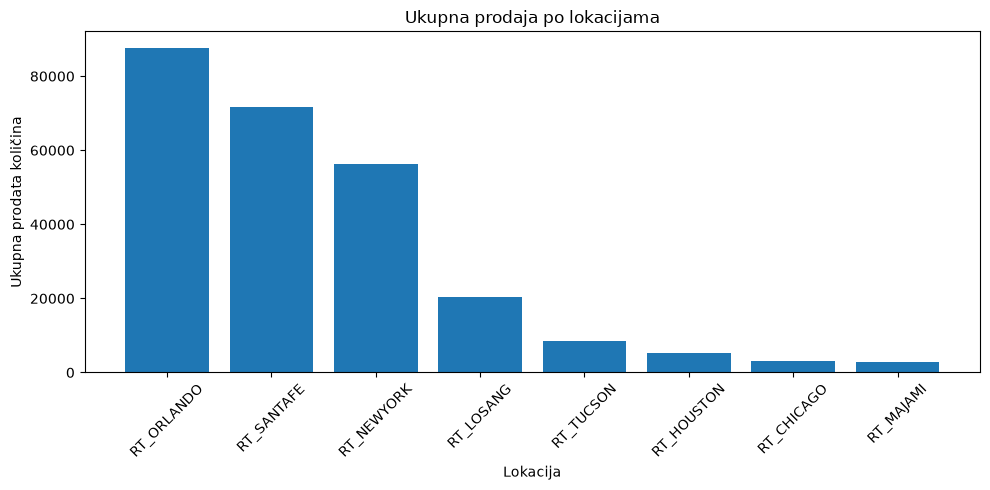

In [12]:
location_summary = (df.groupby("Location Code", as_index=False)["Sold_Quantity"].sum().sort_values("Sold_Quantity", ascending=False))

plt.figure(figsize=(10, 5))
plt.bar(location_summary["Location Code"], location_summary["Sold_Quantity"])
plt.title("Ukupna prodaja po lokacijama")
plt.xlabel("Lokacija")
plt.ylabel("Ukupna prodata količina")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Životni vek prodavnica

Za vremensku seriju je važno **kada** je koja prodavnica radila. Otvaranje i zatvaranje prodavnica menja nivo ukupne prodaje nezavisno od potražnje i predstavlja *strukturnu promenu* u seriji.

In [13]:
LAST_DATE = df["Created Date"].max()

store_life = df.groupby("Location Code")["Created Date"].agg(first_sale="min", last_sale="max")
store_life["aktivna_na_kraju"] = store_life["last_sale"] == LAST_DATE
display(store_life.sort_values("first_sale"))

store_year = df.pivot_table(index="Location Code", columns="Year", values="Sold_Quantity", aggfunc="sum")
store_year

,first_sale,last_sale,aktivna_na_kraju
Location Code,,,
RT_LOSANG,2022-01-03,2025-12-31,True
RT_NEWYORK,2022-01-03,2025-12-31,True
RT_ORLANDO,2022-01-03,2025-12-31,True
RT_CHICAGO,2022-01-10,2023-06-30,False
RT_SANTAFE,2023-01-18,2025-12-31,True
RT_HOUSTON,2024-12-13,2025-12-31,True
RT_TUCSON,2025-01-06,2025-12-31,True
RT_MAJAMI,2025-02-07,2025-12-31,True


Year,2022,2023,2024,2025
Location Code,,,,
RT_CHICAGO,2087.0,1006.0,NaN,NaN
RT_HOUSTON,NaN,NaN,202.0,5081.0
RT_LOSANG,6114.0,3356.0,4574.0,6454.0
RT_MAJAMI,NaN,NaN,NaN,2862.0
RT_NEWYORK,21098.0,11040.0,11890.0,12221.0
RT_ORLANDO,39893.0,15478.0,16640.0,15717.0
RT_SANTAFE,NaN,25605.0,21774.0,24328.0
RT_TUCSON,NaN,NaN,NaN,8393.0


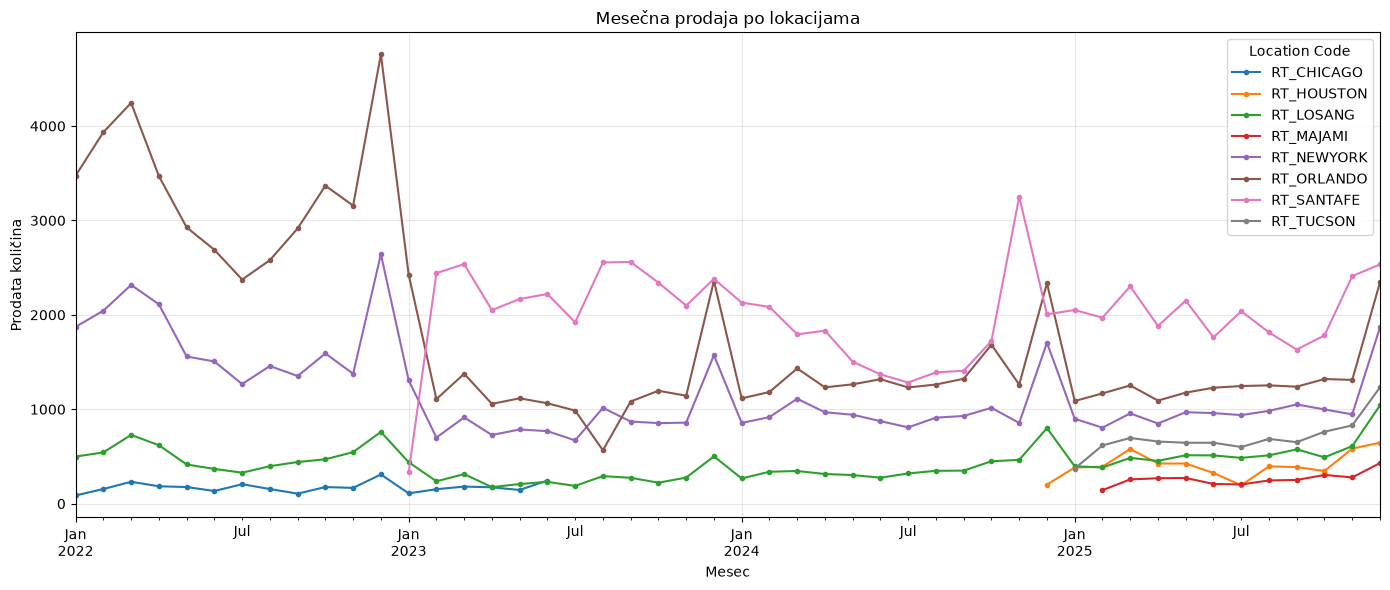

In [14]:
store_month = (df.groupby([pd.Grouper(key="Created Date", freq="MS"), "Location Code"])["Sold_Quantity"].sum().unstack())

store_month.plot(figsize=(14, 6), marker=".")
plt.title("Mesečna prodaja po lokacijama")
plt.xlabel("Mesec")
plt.ylabel("Prodata količina")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- **RT_CHICAGO** je radila samo do juna 2023.
- **RT_SANTAFE** je otvorena u januaru 2023, **RT_HOUSTON** u decembru 2024, a **RT_TUCSON** i **RT_MAJAMI** početkom 2025.
- Pad prodaje 2023. i rast 2025. su zato velikim delom posledica **promene broja prodavnica**, a ne samo promene potražnje. Ova informacija se kasnije uvodi u Prophet kao regresor `active_stores`.

### 4.2 Brendovi i artikli

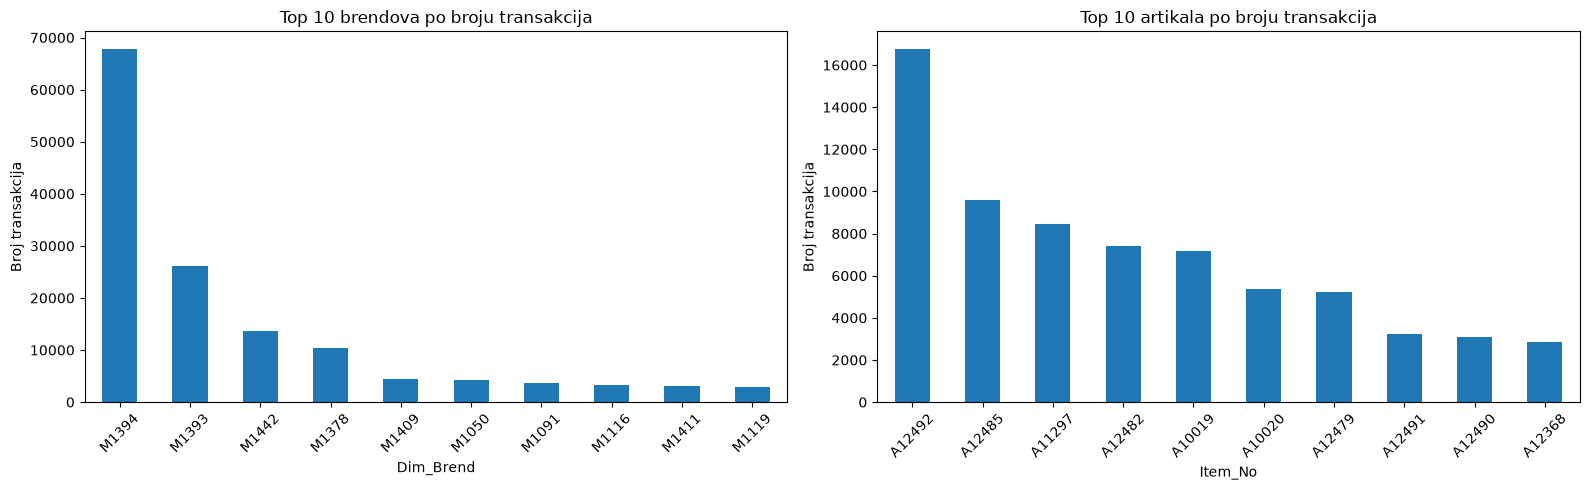

Broj različitih brendova: 435
Broj različitih artikala: 3163
Udeo top 2 brenda u transakcijama: 37.7%


In [15]:
top_brands = df["Dim_Brend"].value_counts().head(10)
top_items = df["Item_No"].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
top_brands.plot(kind="bar", ax=axes[0], title="Top 10 brendova po broju transakcija")
top_items.plot(kind="bar", ax=axes[1], title="Top 10 artikala po broju transakcija")
for ax in axes:
    ax.set_ylabel("Broj transakcija")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

print("Broj različitih brendova:", df["Dim_Brend"].nunique())
print("Broj različitih artikala:", df["Item_No"].nunique())
print("Udeo top 2 brenda u transakcijama: {:.1%}".format(df["Dim_Brend"].value_counts(normalize=True).head(2).sum()))

Prodaja je raspoređena na veliki broj artikala sa malim pojedinačnim količinama (najčešće 1 komad po stavci). Serije pojedinačnih artikala su zato retke i „isprekidane", pa nisu pogodne za Prophet. Prognoza se radi na **agregiranom** nivou (ukupna prodaja lanca).

### 4.3 Vremenska agregacija prodaje

In [16]:
print("Najraniji datum:", df["Created Date"].min().date())
print("Najkasniji datum:", df["Created Date"].max().date())
print("Broj jedinstvenih datuma:", df["Created Date"].nunique())

daily_sales = (df.groupby("Created Date", as_index=False)["Sold_Quantity"].sum().sort_values("Created Date").reset_index(drop=True))

monthly_sales = (df.groupby(pd.Grouper(key="Created Date", freq="MS"))["Sold_Quantity"].sum().reset_index().rename(columns={"Created Date": "YearMonth"}))

yearly_sales = df.groupby("Year", as_index=False)["Sold_Quantity"].sum()

display(daily_sales.head())
display(monthly_sales.tail())
display(yearly_sales)

Najraniji datum: 2022-01-03
Najkasniji datum: 2025-12-31
Broj jedinstvenih datuma: 1435


,Created Date,Sold_Quantity
0,2022-01-03,228
1,2022-01-04,310
2,2022-01-05,281
3,2022-01-06,214
4,2022-01-08,123


,YearMonth,Sold_Quantity
43,2025-08-01,5889
44,2025-09-01,5786
45,2025-10-01,6003
46,2025-11-01,6966
47,2025-12-01,10097


,Year,Sold_Quantity
0,2022,69192
1,2023,56485
2,2024,55080
3,2025,75056


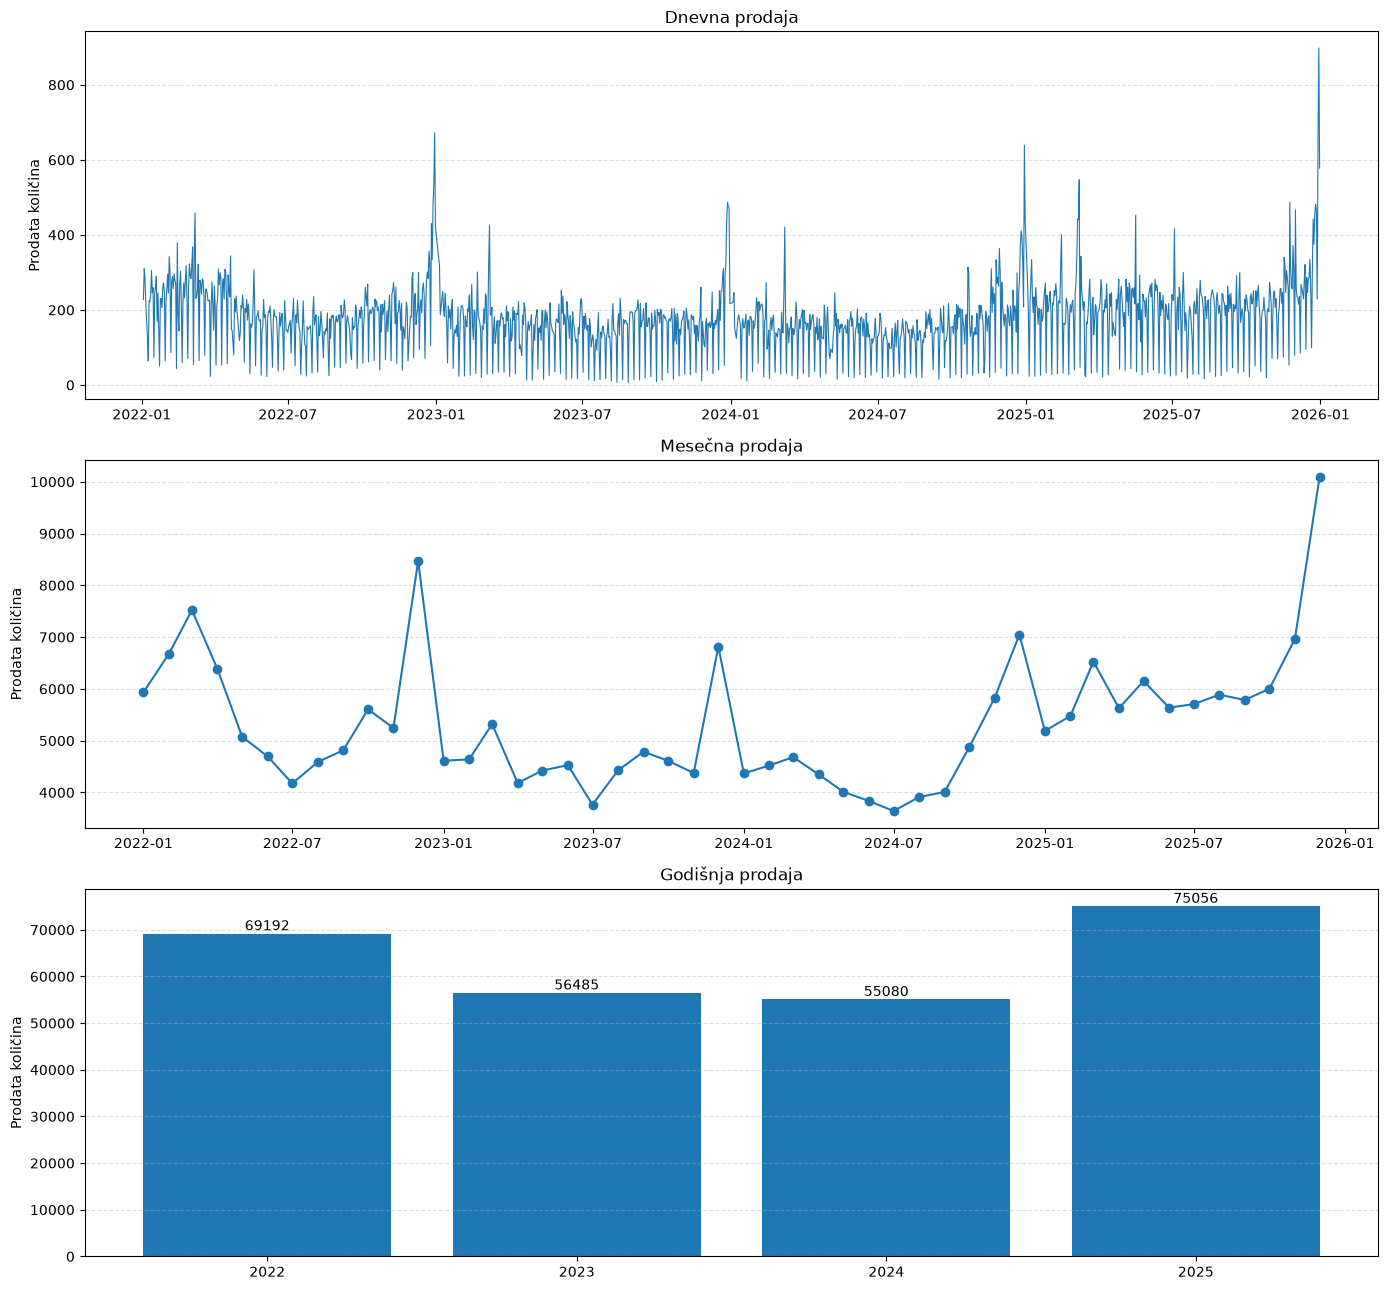

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(14, 13))

axes[0].plot(daily_sales["Created Date"], daily_sales["Sold_Quantity"], linewidth=0.8)
axes[0].set_title("Dnevna prodaja")

axes[1].plot(monthly_sales["YearMonth"], monthly_sales["Sold_Quantity"], marker="o")
axes[1].set_title("Mesečna prodaja")

bars = axes[2].bar(yearly_sales["Year"].astype(str), yearly_sales["Sold_Quantity"])
axes[2].bar_label(bars)
axes[2].set_title("Godišnja prodaja")

for ax in axes:
    ax.set_ylabel("Prodata količina")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [18]:
daily_sales.to_excel("daily_sales.xlsx", index=False)
monthly_sales.to_excel("monthly_sales.xlsx", index=False)
yearly_sales.to_excel("yearly_sales.xlsx", index=False)

### 4.4 Statistika dnevne prodaje i ekstremne vrednosti

count    1435.000000
mean      178.266899
std        87.542119
min         7.000000
25%       139.000000
50%       180.000000
75%       219.000000
max       898.000000
Name: Sold_Quantity, dtype: float64
Koeficijent varijacije: 0.49


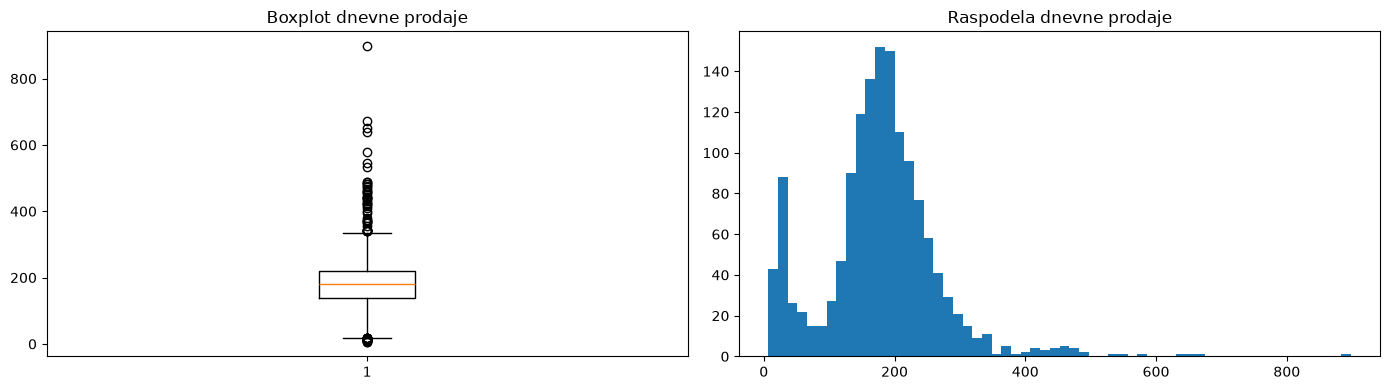

Deset dana sa najvećom prodajom:


,Created Date,Sold_Quantity,Dan
1433,2025-12-30,898,Tuesday
357,2022-12-30,672,Friday
1432,2025-12-29,651,Monday
1074,2024-12-30,639,Monday
1434,2025-12-31,578,Wednesday
1138,2025-03-08,547,Saturday
356,2022-12-29,533,Thursday
712,2023-12-28,487,Thursday
1397,2025-11-24,487,Monday
1429,2025-12-26,482,Friday


In [19]:
print(daily_sales["Sold_Quantity"].describe())
print("Koeficijent varijacije: {:.2f}".format(daily_sales["Sold_Quantity"].std() / daily_sales["Sold_Quantity"].mean()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].boxplot(daily_sales["Sold_Quantity"])
axes[0].set_title("Boxplot dnevne prodaje")
axes[1].hist(daily_sales["Sold_Quantity"], bins=60)
axes[1].set_title("Raspodela dnevne prodaje")
plt.tight_layout()
plt.show()

print("Deset dana sa najvećom prodajom:")
daily_sales.nlargest(10, "Sold_Quantity").assign(Dan=lambda x: x["Created Date"].dt.day_name())

Ekstremno visoke vrednosti **nisu greške** – gotovo sve padaju u poslednje dane decembra (novogodišnja kupovina) i oko 8. marta. To su događaji koji se ponavljaju svake godine, pa ih ne treba brisati, već ih treba **modelovati kao događaje (holidays)** u Prophet-u.

## 5. Analiza kalendara: američki praznici i neradni dani

Lokacije u skupu su američki gradovi, pa se kao kalendar praznika koriste **američki savezni praznici** (US federal holidays). Pre modelovanja proverava se kakav efekat svaki praznik ima na prodaju.

In [20]:
all_dates = pd.date_range(daily_sales["Created Date"].min(), daily_sales["Created Date"].max(), freq="D")
missing_dates = all_dates.difference(daily_sales["Created Date"])

missing_df = pd.DataFrame({"Datum": missing_dates, "Dan": missing_dates.day_name()})
print("Broj dana bez ijedne prodaje:", len(missing_df))
missing_df

Broj dana bez ijedne prodaje: 24


,Datum,Dan
0,2022-01-07,Friday
1,2022-04-24,Sunday
2,2022-05-01,Sunday
3,2022-07-03,Sunday
4,2023-01-01,Sunday
5,2023-01-02,Monday
6,2023-01-03,Tuesday
7,2023-01-07,Saturday
8,2023-01-08,Sunday
9,2023-04-16,Sunday


In [21]:
US_CAL = USFederalHolidayCalendar()

def us_federal_holidays(start, end):
    h = US_CAL.holidays(start=start, end=end, return_name=True)
    return pd.DataFrame({"ds": h.index, "holiday": h.values})

def thanksgiving(year):
    nov = pd.date_range(f"{year}-11-01", f"{year}-11-30", freq="D")
    return nov[nov.weekday == 3][3]

def black_friday(year):
    return thanksgiving(year) + pd.Timedelta(days=1)

us_hol = us_federal_holidays(all_dates.min(), all_dates.max())
print("Američki savezni praznici u periodu 2022–2025:", len(us_hol))
us_hol.head(12)

Američki savezni praznici u periodu 2022–2025: 43


,ds,holiday
0,2022-01-17,"Birthday of Martin Luther King, Jr."
1,2022-02-21,Washington's Birthday
2,2022-05-30,Memorial Day
3,2022-06-20,Juneteenth National Independence Day
4,2022-07-04,Independence Day
5,2022-09-05,Labor Day
6,2022-10-10,Columbus Day
7,2022-11-11,Veterans Day
8,2022-11-24,Thanksgiving Day
9,2022-12-26,Christmas Day


In [22]:
daily_idx = daily_sales.set_index("Created Date")["Sold_Quantity"].reindex(all_dates)
ref_level = daily_idx.rolling(29, center=True, min_periods=10).median()

rows = []
for _, r in us_hol.iterrows():
    rows.append({"Događaj": r["holiday"], "Tip": "US savezni praznik", "Datum": r["ds"]})

for y in range(2022, 2026):
    rows += [{"Događaj": "Valentine's Day (14.2)", "Tip": "Trgovinski događaj", "Datum": pd.Timestamp(f"{y}-02-14")},
             {"Događaj": "International Women's Day (8.3)", "Tip": "Trgovinski događaj", "Datum": pd.Timestamp(f"{y}-03-08")},
             {"Događaj": "Black Friday", "Tip": "Trgovinski događaj", "Datum": black_friday(y)},
             {"Događaj": "Christmas Eve (24.12)", "Tip": "Trgovinski događaj", "Datum": pd.Timestamp(f"{y}-12-24")},
             {"Događaj": "Pred Novu godinu (30.12)", "Tip": "Trgovinski događaj", "Datum": pd.Timestamp(f"{y}-12-30")}]

calendar_check = pd.DataFrame(rows)
calendar_check["Prodaja"] = calendar_check["Datum"].map(daily_idx)
calendar_check["Uobičajeni nivo"] = calendar_check["Datum"].map(ref_level)
calendar_check["Odnos"] = (calendar_check["Prodaja"] / calendar_check["Uobičajeni nivo"]).fillna(0)

calendar_summary = (calendar_check.groupby(["Tip", "Događaj"])
                    .agg(Prosečan_odnos=("Odnos", "mean"),
                         Min_odnos=("Odnos", "min"),
                         Max_odnos=("Odnos", "max"),
                         Broj_zatvorenih_dana=("Prodaja", lambda x: x.isna().sum()))
                    .sort_values("Prosečan_odnos", ascending=False))
calendar_summary.round(2)

Prosečan_odnos  \
Tip                Događaj                                                
Trgovinski događaj Pred Novu godinu (30.12)                        2.43   
                   International Women's Day (8.3)                 2.40   
                   Valentine's Day (14.2)                          1.60   
US savezni praznik Christmas Day                                   1.52   
                   Independence Day                                1.44   
Trgovinski događaj Black Friday                                    1.39   
US savezni praznik Labor Day                                       1.20   
                   Columbus Day                                    1.12   
                   Thanksgiving Day                                1.07   
                   Juneteenth National Independence Day            1.03   
                   Birthday of Martin Luther King, Jr.             1.03   
                   Memorial Day                                    1.00   
Trgovinski događaj Christmas Eve (24.12)                           0.99   
US savezni praznik Washington's Birthday                           0.91   
                   Veterans Day                                    0.77   
                   New Year's Day                                  0.00   

                                                         Min_odnos  Max_odnos  \
Tip                Događaj                                                      
Trgovinski događaj Pred Novu godinu (30.12)                   2.14       2.67   
                   International Women's Day (8.3)            1.70       2.83   
                   Valentine's Day (14.2)                     1.42       1.85   
US savezni praznik Christmas Day                              1.32       1.73   
                   Independence Day                           1.03       2.09   
Trgovinski događaj Black Friday                               1.15       1.73   
US savezni praznik Labor Day                                  1.09       1.35   
                   Columbus Day                               0.96       1.25   
                   Thanksgiving Day                           0.94       1.29   
                   Juneteenth National Independence Day       0.78       1.24   
                   Birthday of Martin Luther King, Jr.        0.92       1.15   
                   Memorial Day                               0.83       1.08   
Trgovinski događaj Christmas Eve (24.12)                      0.24       1.34   
US savezni praznik Washington's Birthday                      0.76       1.08   
                   Veterans Day                               0.37       1.05   
                   New Year's Day                             0.00       0.00   

                                                         Broj_zatvorenih_dana  
Tip                Događaj                                                     
Trgovinski događaj Pred Novu godinu (30.12)                                 0  
                   International Women's Day (8.3)                          0  
                   Valentine's Day (14.2)                                   0  
US savezni praznik Christmas Day                                            0  
                   Independence Day                                         0  
Trgovinski događaj Black Friday                                             0  
US savezni praznik Labor Day                                                0  
                   Columbus Day                                             0  
                   Thanksgiving Day                                         0  
                   Juneteenth National Independence Day                     0  
                   Birthday of Martin Luther King, Jr.                      0  
                   Memorial Day                                             0  
Trgovinski događaj Christmas Eve (24.12)                                    0  
US savezni praznik Washington's Birthday       

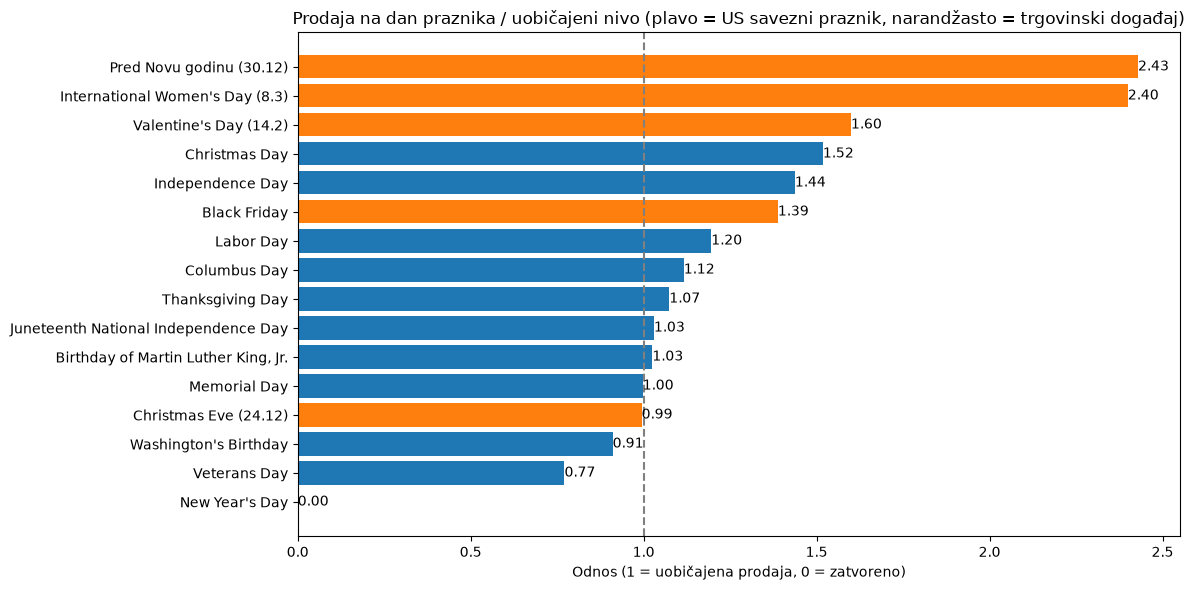

In [23]:
plot_cs = calendar_summary.reset_index()
colors = np.where(plot_cs["Tip"] == "US savezni praznik", "tab:blue", "tab:orange")

plt.figure(figsize=(12, 6))
bars = plt.barh(plot_cs["Događaj"][::-1], plot_cs["Prosečan_odnos"][::-1], color=colors[::-1])
plt.bar_label(bars, fmt="%.2f")
plt.axvline(1, color="grey", linestyle="--")
plt.title("Prodaja na dan praznika / uobičajeni nivo (plavo = US savezni praznik, narandžasto = trgovinski događaj)")
plt.xlabel("Odnos (1 = uobičajena prodaja, 0 = zatvoreno)")
plt.tight_layout()
plt.show()

Kolona *Prosečan_odnos* pokazuje koliko je prodaja tog dana veća ili manja od uobičajenog nivoa (1 = uobičajeno, 0 = zatvoreno):

- **New Year's Day** → prodavnice su **zatvorene** svake godine.
- **Christmas Day** → prodaja je oko **1,5 puta veća** od uobičajene (praznična kupovina poklona).
- **Independence Day** (oko 1,4, sa rastom poslednjih godina) i **Labor Day** (oko 1,2) imaju pozitivan efekat.
- **Martin Luther King Jr. Day, Memorial Day, Juneteenth, Thanksgiving** → prodaja je blizu uobičajene.
- **Washington's Birthday** i **Veterans Day** → prodaja je nešto niža od uobičajene.
- Trgovinski događaji imaju najjači efekat: **8. mart** (≈2,4), **dani pred Novu godinu** (≈2,4), **Valentine's Day** (≈1,6) i **Black Friday** (≈1,4).

Efekti američkih praznika su različiti po smeru i jačini, pa je ispravno da ih Prophet modeluje **svaki posebno** (svaki praznik dobija sopstveni koeficijent), a da slabe efekte „priguši" parametar `holidays_prior_scale`.

Pored New Year's Day, u podacima postoji još nekoliko dana kada prodavnice nisu radile nijedne godine (2. januar, 7. januar, 1. maj i uskršnja nedelja). Oni nisu američki savezni praznici, pa se ne uvode u tabelu praznika, već se tretiraju kao **poznati neradni dani**: izostavljaju se iz treniranja, a u prognozi se postavljaju na 0.

## 6. Analiza sezonalnosti i karakteristika skupa u odnosu na model
### 6.1 Nedeljna sezonalnost

Day,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Year,,,,,,,
2022,205.5,212.0,213.2,217.8,232.0,204.6,54.1
2023,177.0,175.7,180.4,178.8,186.2,178.3,28.0
2024,177.8,170.9,167.7,166.1,182.8,168.5,30.3
2025,241.7,245.6,233.1,235.0,248.9,216.2,42.2


Day,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Year,,,,,,,
2022,0.96,0.99,1.00,1.02,1.08,0.96,0.25
2023,0.99,0.98,1.01,1.00,1.04,0.99,0.16
2024,1.03,0.99,0.97,0.96,1.06,0.98,0.18
2025,1.02,1.04,0.98,0.99,1.05,0.91,0.18


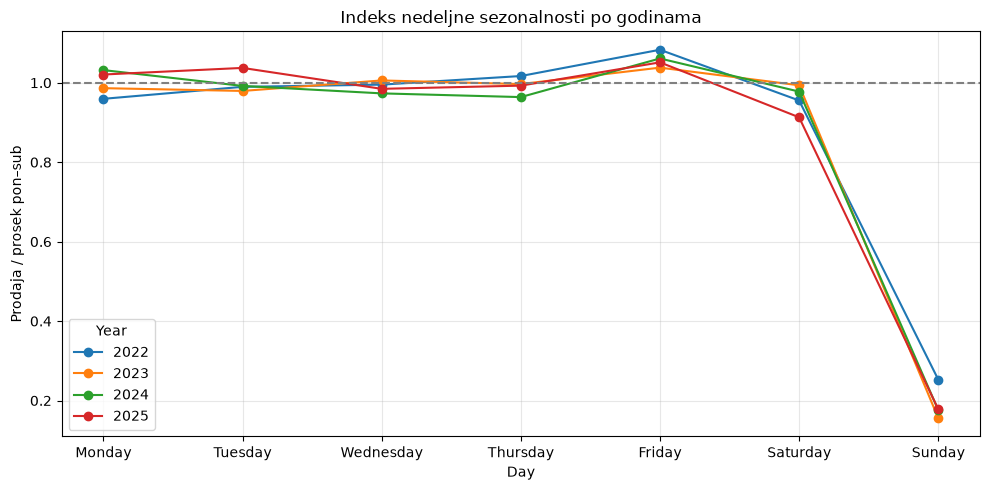

In [24]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

ds_tmp = daily_sales.assign(Day=daily_sales["Created Date"].dt.day_name(),
                            Year=daily_sales["Created Date"].dt.year)

weekday_mean = ds_tmp.pivot_table(index="Year", columns="Day", values="Sold_Quantity", aggfunc="mean")[day_order]

weekday_index = weekday_mean.div(weekday_mean[day_order[:6]].mean(axis=1), axis=0)

display(weekday_mean.round(1))
display(weekday_index.round(2))

weekday_index.T.plot(marker="o", figsize=(10, 5))
plt.axhline(1, color="grey", linestyle="--")
plt.title("Indeks nedeljne sezonalnosti po godinama")
plt.ylabel("Prodaja / prosek pon–sub")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- Od ponedeljka do subote prodaja je ujednačena (petak je nešto jači).
- **Nedelja ima samo 16–25% prodaje običnog dana** (skraćeno radno vreme ili neradna nedelja u delu prodavnica).
- Oblik nedeljne krive je **isti u svim godinama**, iako se nivo prodaje menja. To znači da je sezonalnost *proporcionalna nivou* – argument za `seasonality_mode="multiplicative"`.

### 6.2 Godišnja (mesečna) sezonalnost

Year,2022,2023,2024,2025
Month,,,,
1,5934.0,4613.0,4367.0,5188.0
2,6677.0,4639.0,4522.0,5478.0
3,7522.0,5321.0,4682.0,6527.0
4,6385.0,4182.0,4347.0,5628.0
5,5077.0,4423.0,4013.0,6151.0
6,4697.0,4528.0,3836.0,5638.0
7,4175.0,3765.0,3642.0,5705.0
8,4589.0,4427.0,3912.0,5889.0
9,4814.0,4786.0,4009.0,5786.0


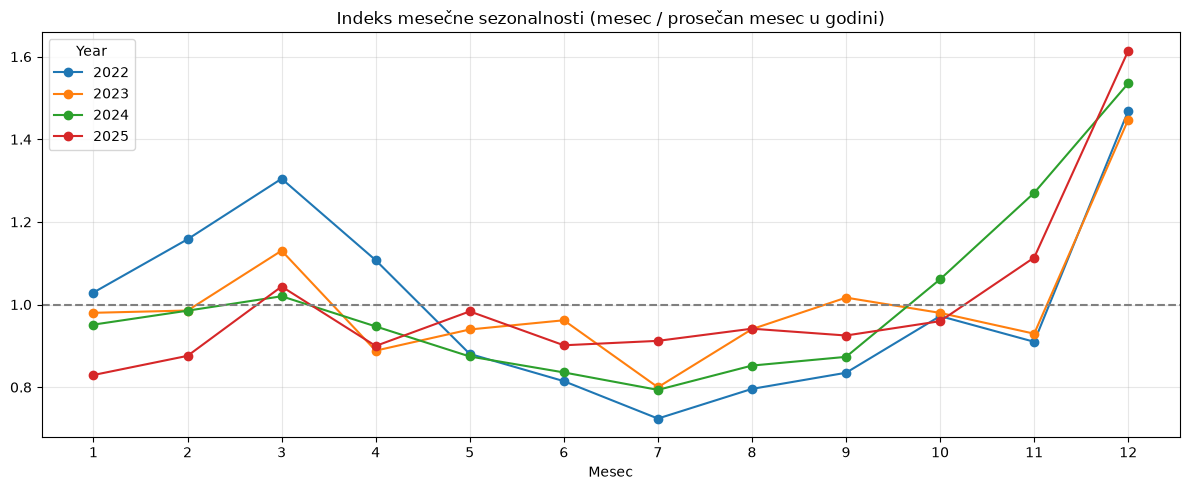

In [25]:
m_tmp = monthly_sales.assign(Year=monthly_sales["YearMonth"].dt.year, Month=monthly_sales["YearMonth"].dt.month)
month_pivot = m_tmp.pivot_table(index="Month", columns="Year", values="Sold_Quantity")
month_index = month_pivot / month_pivot.mean()

display(month_pivot)

month_index.plot(marker="o", figsize=(12, 5))
plt.axhline(1, color="grey", linestyle="--")
plt.xticks(range(1, 13))
plt.title("Indeks mesečne sezonalnosti (mesec / prosečan mesec u godini)")
plt.xlabel("Mesec")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

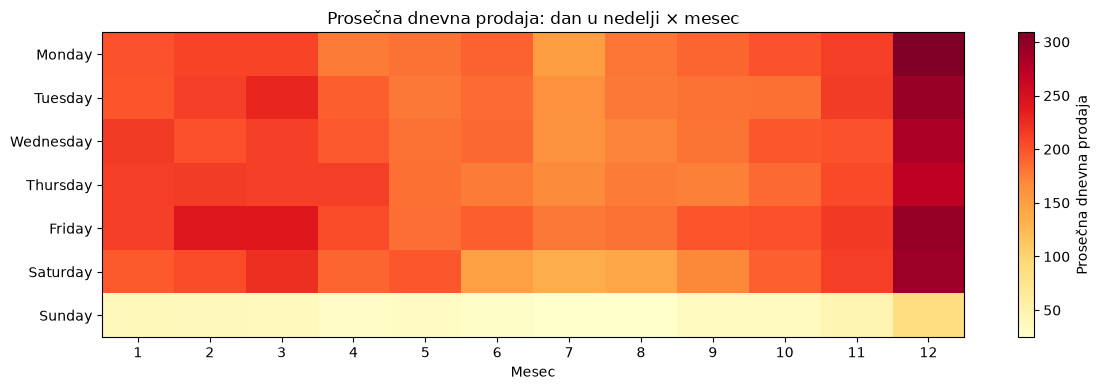

In [26]:
heat = ds_tmp.assign(Month=ds_tmp["Created Date"].dt.month).pivot_table(
    index="Day", columns="Month", values="Sold_Quantity", aggfunc="mean").loc[day_order]

plt.figure(figsize=(12, 4))
plt.imshow(heat, aspect="auto", cmap="YlOrRd")
plt.colorbar(label="Prosečna dnevna prodaja")
plt.yticks(range(7), day_order)
plt.xticks(range(12), range(1, 13))
plt.xlabel("Mesec")
plt.title("Prosečna dnevna prodaja: dan u nedelji × mesec")
plt.tight_layout()
plt.show()

- **Decembar** je najjači mesec u svakoj godini (1,4–1,7 puta više od prosečnog meseca).
- **Mart** je izdvojen zbog 8. marta, a februar je nešto jači zbog 14. februara.
- **Leto** (jun–avgust) je najslabiji period.

### 6.3 Trend i autokorelacija

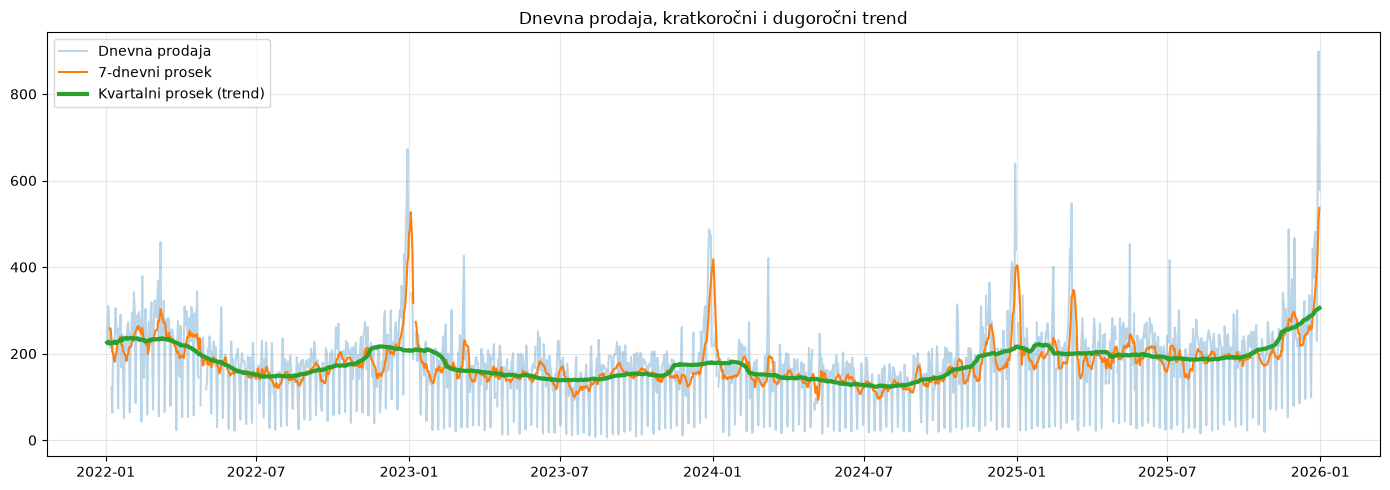

In [27]:
series = daily_sales.set_index("Created Date")["Sold_Quantity"].reindex(all_dates)

plt.figure(figsize=(14, 5))
plt.plot(series.index, series, alpha=0.3, label="Dnevna prodaja")
plt.plot(series.index, series.rolling(7, min_periods=4).mean(), label="7-dnevni prosek")
plt.plot(series.index, series.rolling(91, center=True, min_periods=30).mean(), linewidth=3, label="Kvartalni prosek (trend)")
plt.title("Dnevna prodaja, kratkoročni i dugoročni trend")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

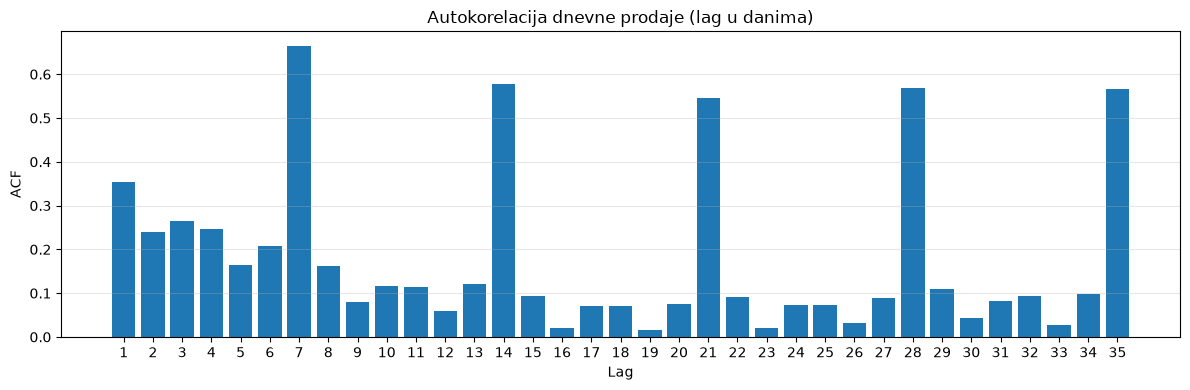

ACF lag 7:   0.66
ACF lag 364: 0.64


In [28]:
s_interp = series.interpolate()
lags = list(range(1, 36))
acf_vals = [s_interp.autocorr(l) for l in lags]

plt.figure(figsize=(12, 4))
plt.bar(lags, acf_vals)
plt.xticks(lags)
plt.title("Autokorelacija dnevne prodaje (lag u danima)")
plt.xlabel("Lag")
plt.ylabel("ACF")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("ACF lag 7:   {:.2f}".format(s_interp.autocorr(7)))
print("ACF lag 364: {:.2f}".format(s_interp.autocorr(364)))

Autokorelacija ima izražene vrhove na **7, 14, 21, 28... dana** (nedeljni ciklus), a pozitivna je i na razmaku od godinu dana (lag 364). To potvrđuje nedeljnu i godišnju sezonalnost.

### 6.4 Sažetak: karakteristike skupa → odluke o modelu

| Karakteristika skupa | Posledica za Prophet |
|---|---|
| Transakcioni podaci, većinom 1 komad po stavci | agregacija na dnevni nivo (`ds`, `y`) |
| Korekcije zaliha i povraćaji u istoj tabeli | koristi se samo `Sale`, neto količina |
| 24 dana bez prodaje (New Year's Day i drugi neradni dani) | dani se **izostavljaju** (ne popunjavaju nulom); poznati neradni dani se u prognozi postavljaju na 0 |
| Jaka nedeljna sezonalnost (nedelja ≈ 20% običnog dana), stabilnog oblika | nedeljna sezonalnost, **multiplikativni** režim |
| Godišnja sezonalnost (jak decembar, slabo leto) | godišnja sezonalnost (Furijeov red) |
| Oštri pikovi: 8. mart, Valentine's Day, praznična sezona u decembru, Black Friday | **događaji sa prozorima** (`lower_window`, `upper_window`) |
| Američki praznici sa različitim efektima (od 0 do ≈1,5) | tabela **US saveznih praznika**, svaki sa sopstvenim koeficijentom |
| Promena broja prodavnica (3 → 7) | regresor **`active_stores`** (poznat unapred) |
| Samo 4 godine podataka | godišnji nivo nije pogodan za Prophet; godišnja prognoza se dobija sabiranjem dnevne |

## 7. Priprema podataka za Prophet
### 7.1 Američki praznici i trgovinski događaji

Tabela praznika u formatu koji zahteva Prophet (`holiday`, `ds`, `lower_window`, `upper_window`) sastoji se od:

- **US saveznih praznika** (New Year's Day, Martin Luther King Jr. Day, Washington's Birthday, Memorial Day, Juneteenth, Independence Day, Labor Day, Columbus Day, Veterans Day, Thanksgiving, Christmas Day),
- **trgovinskih događaja** sa prozorima koji obuhvataju i kupovinu pre samog datuma: Valentine's Day, International Women's Day, Black Friday (od Thanksgiving nedelje do Cyber Monday) i praznične sezone od 17. do 31. decembra.

In [29]:
def us_holidays_and_events(years):
    years = list(years)
    hol = us_federal_holidays(f"{years[0]}-01-01", f"{years[-1]}-12-31")
    hol["lower_window"] = 0
    hol["upper_window"] = 0

    events = []
    def add(name, date, lower=0, upper=0):
        events.append({"holiday": name, "ds": pd.Timestamp(date), "lower_window": lower, "upper_window": upper})

    for y in years:
        add("Valentines_Day", f"{y}-02-14", -2, 0)
        add("International_Womens_Day", f"{y}-03-08", -4, 0)
        add("Black_Friday", black_friday(y), -4, 3)             
        add("Holiday_Season", f"{y}-12-31", -14, 0)             

    return pd.concat([hol, pd.DataFrame(events)], ignore_index=True)[["holiday", "ds", "lower_window", "upper_window"]]


def closed_days(years):
    dates = []
    for y in years:
        dates += [f"{y}-01-01", f"{y}-01-02", f"{y}-01-07", f"{y}-05-01",
                  pd.Timestamp(easter(y, EASTER_ORTHODOX))]
    return pd.DatetimeIndex(pd.to_datetime(dates))


YEARS = range(2022, 2028)
HOLIDAYS = us_holidays_and_events(YEARS)
CLOSED_DAYS = closed_days(YEARS)

print("Broj redova u tabeli praznika:", len(HOLIDAYS))
display(HOLIDAYS["holiday"].value_counts())
HOLIDAYS[HOLIDAYS["ds"].dt.year == 2025].sort_values("ds")

Broj redova u tabeli praznika: 90


holiday
Birthday of Martin Luther King, Jr.     6
Washington's Birthday                   6
Memorial Day                            6
Juneteenth National Independence Day    6
Independence Day                        6
Labor Day                               6
Columbus Day                            6
Veterans Day                            6
Thanksgiving Day                        6
Christmas Day                           6
New Year's Day                          6
Valentines_Day                          6
International_Womens_Day                6
Black_Friday                            6
Holiday_Season                          6
Name: count, dtype: int64

,holiday,ds,lower_window,upper_window
32,New Year's Day,2025-01-01,0,0
33,"Birthday of Martin Luther King, Jr.",2025-01-20,0,0
78,Valentines_Day,2025-02-14,-2,0
34,Washington's Birthday,2025-02-17,0,0
79,International_Womens_Day,2025-03-08,-4,0
35,Memorial Day,2025-05-26,0,0
36,Juneteenth National Independence Day,2025-06-19,0,0
37,Independence Day,2025-07-04,0,0
38,Labor Day,2025-09-01,0,0
39,Columbus Day,2025-10-13,0,0


### 7.2 Regresor: broj aktivnih prodavnica

Za svaki dan se računa broj prodavnica koje su u tom trenutku poslovale (između prve i poslednje prodaje). Za budući period pretpostavlja se da nastavljaju da rade prodavnice koje su bile aktivne na kraju 2025. godine (7 prodavnica). Ova vrednost je poznata unapred (plan otvaranja/zatvaranja), pa je regresor ispravan i za prognozu.

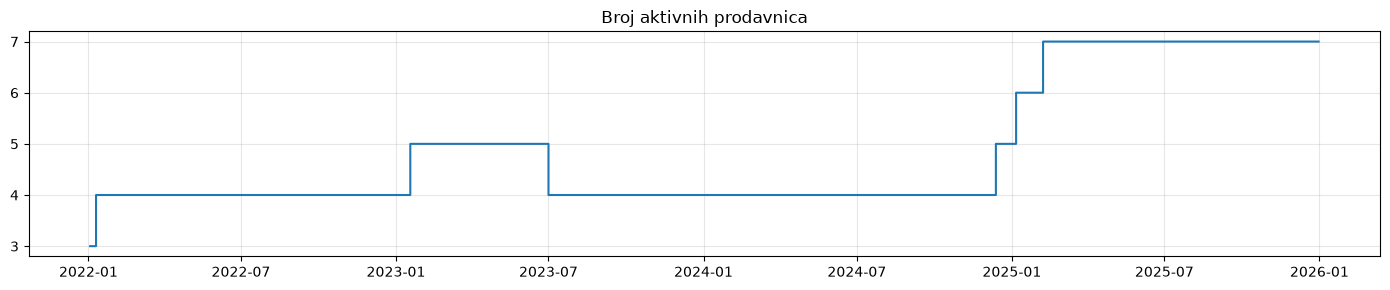

In [30]:
def active_stores(dates):
    dates = pd.to_datetime(pd.Series(dates)).reset_index(drop=True)
    count = np.zeros(len(dates), dtype=int)
    for _, row in store_life.iterrows():
        end = pd.Timestamp.max if row["aktivna_na_kraju"] else row["last_sale"]
        count += ((dates >= row["first_sale"]) & (dates <= end)).to_numpy().astype(int)
    return count

tmp = pd.DataFrame({"ds": all_dates})
tmp["active_stores"] = active_stores(tmp["ds"])
plt.figure(figsize=(14, 3))
plt.step(tmp["ds"], tmp["active_stores"], where="post")
plt.title("Broj aktivnih prodavnica")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.3 Formiranje ulazne tabele `ds`, `y`

Ranije su dani bez prodaje popunjavani nulom (`reindex(..., fill_value=0)`), zbog čega je model „učio" da prodaja pada na nulu i na dane kada to nije realno. Sada se ti dani **izostavljaju**.

In [31]:
prophet_df = daily_sales.rename(columns={"Created Date": "ds", "Sold_Quantity": "y"})[["ds", "y"]].copy()
prophet_df["active_stores"] = active_stores(prophet_df["ds"])

print("Broj dana u seriji:", len(prophet_df))
print("Nedostajuće vrednosti:", prophet_df.isnull().sum().sum())
prophet_df.head()

Broj dana u seriji: 1435
Nedostajuće vrednosti: 0


,ds,y,active_stores
0,2022-01-03,228,3
1,2022-01-04,310,3
2,2022-01-05,281,3
3,2022-01-06,214,3
4,2022-01-08,123,3


### 7.4 Podela na skup za treniranje i test

Poslednji kvartal 2025. godine (1. oktobar – 31. decembar) koristi se kao **test skup**. To je najzahtevniji deo godine jer sadrži Black Friday i novogodišnju sezonu, pa dobro pokazuje da li model hvata sezonske pikove. Na trening skupu se radi i unakrsna validacija za optimizaciju hiperparametara.

In [32]:
TEST_START = pd.Timestamp("2025-10-01")

train = prophet_df[prophet_df["ds"] < TEST_START].copy()
test = prophet_df[prophet_df["ds"] >= TEST_START].copy()

print("Train:", train["ds"].min().date(), "–", train["ds"].max().date(), train.shape)
print("Test: ", test["ds"].min().date(), "–", test["ds"].max().date(), test.shape)

Train: 2022-01-03 – 2025-09-30 (1343, 3)
Test:  2025-10-01 – 2025-12-31 (92, 3)


## 8. Referentni modeli i pomoćne funkcije

Da bi se procenilo da li Prophet donosi stvarnu vrednost, poredi se sa dva jednostavna modela:

1. **Sezonski naivni model** – za svaki dan u nedelji prognoza je poslednja poznata vrednost istog dana u nedelji.
2. **Prosek dana u nedelji** – prosek istog dana u nedelji tokom poslednjih 8 nedelja trening skupa.

Metrike:
- **MAE** – prosečna apsolutna greška (u komadima),
- **RMSE** – koren srednje kvadratne greške (više kažnjava velike promašaje),
- **MAPE** – prosečna procentualna greška (osetljiva na dane sa malom prodajom, npr. nedelje),
- **WAPE** – ukupna apsolutna greška / ukupna prodaja; za maloprodaju je najpouzdanija procentualna mera.

In [33]:
def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    err = y_true - y_pred
    mask = y_true > 0
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAPE (%)": np.mean(np.abs(err[mask] / y_true[mask])) * 100,
        "WAPE (%)": np.abs(err).sum() / y_true.sum() * 100,
    }

results = {}          
predictions = {}      

last_by_weekday = train.groupby(train["ds"].dt.weekday)["y"].last()
predictions["Sezonski naivni"] = test["ds"].dt.weekday.map(last_by_weekday).to_numpy()

recent = train[train["ds"] >= train["ds"].max() - pd.Timedelta(days=55)]
mean_by_weekday = recent.groupby(recent["ds"].dt.weekday)["y"].mean()
predictions["Prosek dana u nedelji (8 ned.)"] = test["ds"].dt.weekday.map(mean_by_weekday).to_numpy()

for name in predictions:
    results[name] = evaluate(test["y"], predictions[name])

pd.DataFrame(results).T.round(2)

,MAE,RMSE,MAPE (%),WAPE (%)
Sezonski naivni,84.48,134.69,30.20,33.69
Prosek dana u nedelji (8 ned.),70.37,122.72,25.42,28.07


In [34]:
def build_model(params=None, use_holidays=True, use_regressor=True):
    params = dict(params or {})
    model = Prophet(holidays=HOLIDAYS if use_holidays else None, **params)
    if use_regressor:
        model.add_regressor("active_stores")
    return model


def predict_clean(model, frame):
    fc = model.predict(frame)
    for col in ["yhat", "yhat_lower", "yhat_upper"]:
        fc[col] = fc[col].clip(lower=0)
        fc.loc[fc["ds"].isin(CLOSED_DAYS), col] = 0
    return fc


def fit_and_evaluate(name, model, regressor_cols=("active_stores",)):
    cols = ["ds", "y"] + [c for c in regressor_cols if c in train.columns]
    model.fit(train[cols])
    fc = predict_clean(model, test[cols[:1] + cols[2:]])
    predictions[name] = fc["yhat"].to_numpy()
    results[name] = evaluate(test["y"], fc["yhat"])
    print(name, {k: round(float(v), 2) for k, v in results[name].items()})
    return model, fc

## 9. Prophet modeli – postepeno unapređenje

| Model | Opis |
|---|---|
| **M0** | podrazumevani Prophet, bez praznika i regresora |
| **M1** | M0 + američki praznici i trgovinski događaji |
| **M2** | M1 + multiplikativna sezonalnost + regresor `active_stores` |
| **M3** | M2 sa hiperparametrima izabranim unakrsnom validacijom |

In [35]:
m0, fc0 = fit_and_evaluate("M0: Prophet podrazumevani", build_model(use_holidays=False, use_regressor=False), regressor_cols=())

m1, fc1 = fit_and_evaluate("M1: + US praznici i događaji", build_model(use_holidays=True, use_regressor=False), regressor_cols=())

m2, fc2 = fit_and_evaluate("M2: + multiplikativno + active_stores", build_model({"seasonality_mode": "multiplicative"}))

20:52:19 - cmdstanpy - INFO - Chain [1] start processing
20:52:20 - cmdstanpy - INFO - Chain [1] done processing


M0: Prophet podrazumevani {'MAE': 51.29, 'RMSE': 83.85, 'MAPE (%)': 28.88, 'WAPE (%)': 20.46}


20:52:21 - cmdstanpy - INFO - Chain [1] start processing
20:52:22 - cmdstanpy - INFO - Chain [1] done processing


M1: + US praznici i događaji {'MAE': 42.08, 'RMSE': 59.38, 'MAPE (%)': 27.64, 'WAPE (%)': 16.79}


20:52:23 - cmdstanpy - INFO - Chain [1] start processing
20:52:23 - cmdstanpy - INFO - Chain [1] done processing


M2: + multiplikativno + active_stores {'MAE': 45.81, 'RMSE': 58.47, 'MAPE (%)': 24.27, 'WAPE (%)': 18.27}


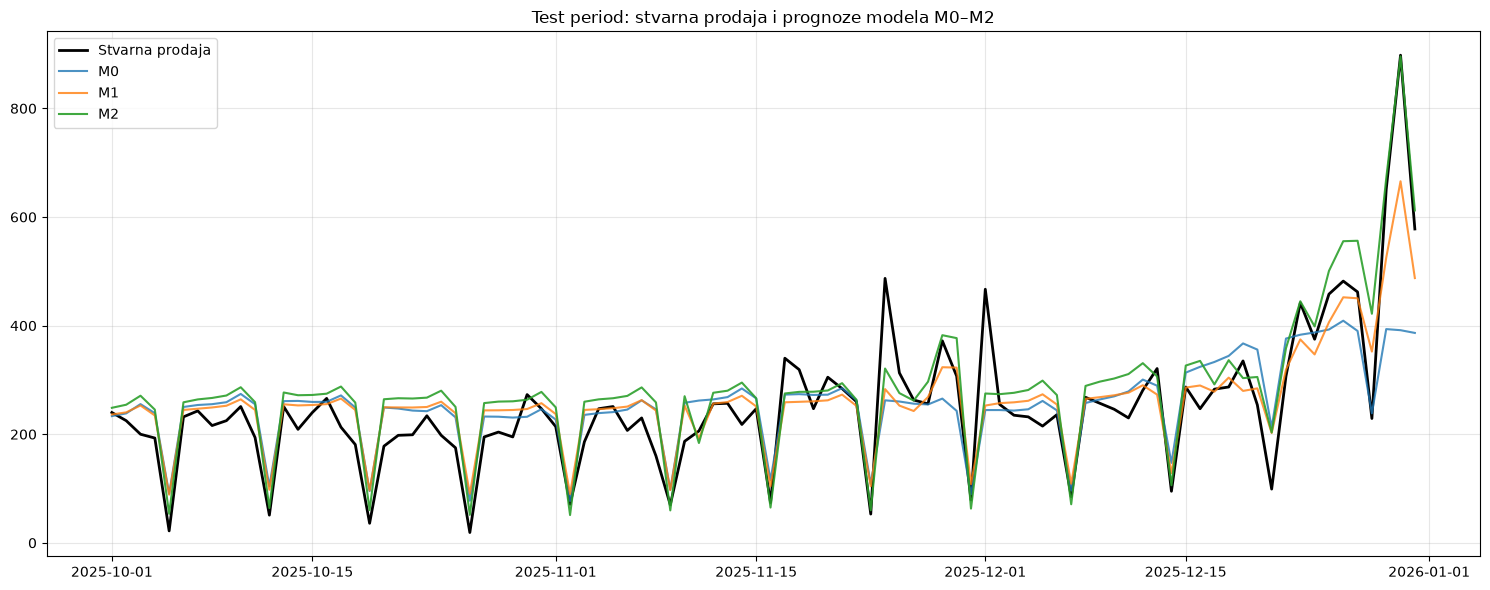

In [36]:
plt.figure(figsize=(15, 6))
plt.plot(test["ds"], test["y"], color="black", linewidth=2, label="Stvarna prodaja")
plt.plot(test["ds"], predictions["M0: Prophet podrazumevani"], label="M0", alpha=0.8)
plt.plot(test["ds"], predictions["M1: + US praznici i događaji"], label="M1", alpha=0.8)
plt.plot(test["ds"], predictions["M2: + multiplikativno + active_stores"], label="M2", alpha=0.9)
plt.title("Test period: stvarna prodaja i prognoze modela M0–M2")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Optimizacija hiperparametara (unakrsna validacija)

Hiperparametri se biraju **isključivo na trening skupu**, unakrsnom validacijom za vremenske serije:

- `initial = 730 days` – model se prvi put trenira na 2 godine podataka (potrebno za godišnju sezonalnost),
- `period = 120 days` – razmak između dva preseka (*cutoff*),
- `horizon = 90 days` – dužina prognoze koja se ocenjuje (isto kao test skup).

Pretražuje se mreža vrednosti za fleksibilnost trenda, jačinu sezonalnosti, jačinu praznika i režim sezonalnosti, a kriterijum izbora je **MAE**.

In [37]:
RUN_GRID_SEARCH = True

param_grid = {
    "changepoint_prior_scale": [0.01, 0.05, 0.1, 0.3],
    "seasonality_prior_scale": [1.0, 10.0],
    "holidays_prior_scale": [1.0, 10.0],
    "seasonality_mode": ["additive", "multiplicative"],
}
all_params = [dict(zip(param_grid.keys(), v)) for v in itertools.product(*param_grid.values())]

if RUN_GRID_SEARCH:
    cv_rows = []
    for i, params in enumerate(all_params, 1):
        m = build_model(params)
        m.fit(train[["ds", "y", "active_stores"]])
        df_cv = cross_validation(m, initial="730 days", period="120 days", horizon="90 days",
                                 disable_tqdm=True)
        df_p = performance_metrics(df_cv, rolling_window=1)
        cv_rows.append({**params,
                        "mae": df_p["mae"].values[0],
                        "rmse": df_p["rmse"].values[0],
                        "coverage": df_p["coverage"].values[0]})
        print(f"{i}/{len(all_params)} {params} -> MAE={cv_rows[-1]['mae']:.2f}")
    tuning_results = pd.DataFrame(cv_rows).sort_values("mae").reset_index(drop=True)
    best_params = tuning_results.iloc[0][list(param_grid.keys())].to_dict()
else:
    best_params = {"changepoint_prior_scale": 0.05, "seasonality_prior_scale": 10.0,
                   "holidays_prior_scale": 10.0, "seasonality_mode": "multiplicative"}
    tuning_results = None

print("\nNajbolji parametri:", best_params)
tuning_results.head(10) if tuning_results is not None else None

20:52:25 - cmdstanpy - INFO - Chain [1] start processing
20:52:25 - cmdstanpy - INFO - Chain [1] done processing
20:52:26 - cmdstanpy - INFO - Chain [1] start processing
20:52:26 - cmdstanpy - INFO - Chain [1] done processing
20:52:27 - cmdstanpy - INFO - Chain [1] start processing
20:52:27 - cmdstanpy - INFO - Chain [1] done processing
20:52:28 - cmdstanpy - INFO - Chain [1] start processing
20:52:28 - cmdstanpy - INFO - Chain [1] done processing
20:52:29 - cmdstanpy - INFO - Chain [1] start processing
20:52:29 - cmdstanpy - INFO - Chain [1] done processing
20:52:30 - cmdstanpy - INFO - Chain [1] start processing
20:52:30 - cmdstanpy - INFO - Chain [1] done processing


1/32 {'changepoint_prior_scale': 0.01, 'seasonality_prior_scale': 1.0, 'holidays_prior_scale': 1.0, 'seasonality_mode': 'additive'} -> MAE=37.98


20:52:31 - cmdstanpy - INFO - Chain [1] start processing
20:52:32 - cmdstanpy - INFO - Chain [1] done processing
20:52:33 - cmdstanpy - INFO - Chain [1] start processing
20:52:33 - cmdstanpy - INFO - Chain [1] done processing
20:52:34 - cmdstanpy - INFO - Chain [1] start processing
20:52:34 - cmdstanpy - INFO - Chain [1] done processing
20:52:35 - cmdstanpy - INFO - Chain [1] start processing
20:52:35 - cmdstanpy - INFO - Chain [1] done processing
20:52:36 - cmdstanpy - INFO - Chain [1] start processing
20:52:37 - cmdstanpy - INFO - Chain [1] done processing
20:52:37 - cmdstanpy - INFO - Chain [1] start processing
20:52:38 - cmdstanpy - INFO - Chain [1] done processing


2/32 {'changepoint_prior_scale': 0.01, 'seasonality_prior_scale': 1.0, 'holidays_prior_scale': 1.0, 'seasonality_mode': 'multiplicative'} -> MAE=36.81


20:52:39 - cmdstanpy - INFO - Chain [1] start processing
20:52:40 - cmdstanpy - INFO - Chain [1] done processing
20:52:40 - cmdstanpy - INFO - Chain [1] start processing
20:52:40 - cmdstanpy - INFO - Chain [1] done processing
20:52:41 - cmdstanpy - INFO - Chain [1] start processing
20:52:43 - cmdstanpy - INFO - Chain [1] done processing
20:52:44 - cmdstanpy - INFO - Chain [1] start processing
20:52:45 - cmdstanpy - INFO - Chain [1] done processing
20:52:45 - cmdstanpy - INFO - Chain [1] start processing
20:52:46 - cmdstanpy - INFO - Chain [1] done processing
20:52:47 - cmdstanpy - INFO - Chain [1] start processing
20:52:47 - cmdstanpy - INFO - Chain [1] done processing


3/32 {'changepoint_prior_scale': 0.01, 'seasonality_prior_scale': 1.0, 'holidays_prior_scale': 10.0, 'seasonality_mode': 'additive'} -> MAE=37.69


... (55 outputs left out)

31/32 {'changepoint_prior_scale': 0.3, 'seasonality_prior_scale': 10.0, 'holidays_prior_scale': 10.0, 'seasonality_mode': 'additive'} -> MAE=40.69


20:56:32 - cmdstanpy - INFO - Chain [1] start processing
20:56:33 - cmdstanpy - INFO - Chain [1] done processing
20:56:33 - cmdstanpy - INFO - Chain [1] start processing
20:56:34 - cmdstanpy - INFO - Chain [1] done processing
20:56:35 - cmdstanpy - INFO - Chain [1] start processing
20:56:35 - cmdstanpy - INFO - Chain [1] done processing
20:56:36 - cmdstanpy - INFO - Chain [1] start processing
20:56:37 - cmdstanpy - INFO - Chain [1] done processing
20:56:37 - cmdstanpy - INFO - Chain [1] start processing
20:56:38 - cmdstanpy - INFO - Chain [1] done processing
20:56:39 - cmdstanpy - INFO - Chain [1] start processing
20:56:39 - cmdstanpy - INFO - Chain [1] done processing


32/32 {'changepoint_prior_scale': 0.3, 'seasonality_prior_scale': 10.0, 'holidays_prior_scale': 10.0, 'seasonality_mode': 'multiplicative'} -> MAE=34.80

Najbolji parametri: {'changepoint_prior_scale': 0.05, 'seasonality_prior_scale': 1.0, 'holidays_prior_scale': 10.0, 'seasonality_mode': 'multiplicative'}


,changepoint_prior_scale,seasonality_prior_scale,holidays_prior_scale,seasonality_mode,mae,rmse,coverage
0,0.05,1.0,10.0,multiplicative,34.782675,50.333281,0.727891
1,0.30,10.0,10.0,multiplicative,34.796940,50.054827,0.730159
2,0.30,1.0,10.0,multiplicative,34.800590,50.067740,0.721088
3,0.05,10.0,10.0,multiplicative,34.810212,50.358920,0.725624
4,0.05,10.0,1.0,multiplicative,34.843542,50.373065,0.718821
5,0.05,1.0,1.0,multiplicative,34.852632,50.409001,0.716553
6,0.30,1.0,1.0,multiplicative,34.906219,50.130047,0.725624
7,0.30,10.0,1.0,multiplicative,34.948840,50.221091,0.732426
8,0.10,1.0,10.0,multiplicative,34.977747,50.627305,0.727891
9,0.10,10.0,10.0,multiplicative,35.045299,50.696763,0.725624


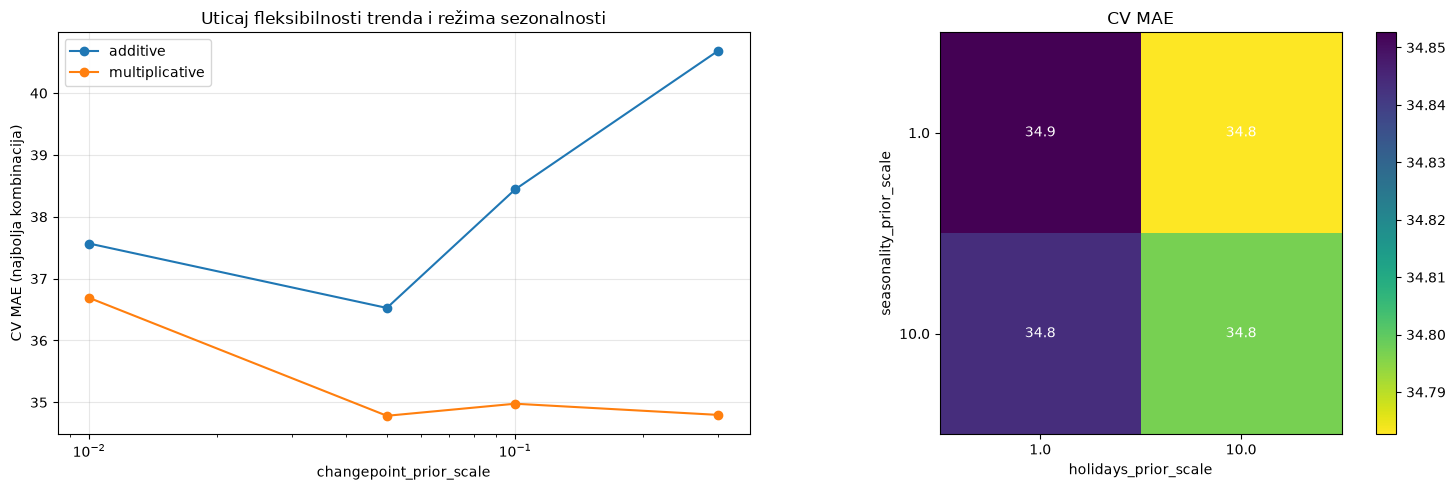

In [38]:
if tuning_results is not None:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    for mode, grp in tuning_results.groupby("seasonality_mode"):
        g = grp.groupby("changepoint_prior_scale")["mae"].min()
        axes[0].plot(g.index, g.values, marker="o", label=mode)
    axes[0].set_xscale("log")
    axes[0].set_xlabel("changepoint_prior_scale")
    axes[0].set_ylabel("CV MAE (najbolja kombinacija)")
    axes[0].set_title("Uticaj fleksibilnosti trenda i režima sezonalnosti")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    pv = tuning_results.pivot_table(index="seasonality_prior_scale", columns="holidays_prior_scale",
                                    values="mae", aggfunc="min")
    im = axes[1].imshow(pv, cmap="viridis_r")
    axes[1].set_xticks(range(len(pv.columns)), pv.columns)
    axes[1].set_yticks(range(len(pv.index)), pv.index)
    axes[1].set_xlabel("holidays_prior_scale")
    axes[1].set_ylabel("seasonality_prior_scale")
    axes[1].set_title("CV MAE")
    for (r, c), v in np.ndenumerate(pv.values):
        axes[1].text(c, r, f"{v:.1f}", ha="center", va="center", color="white")
    plt.colorbar(im, ax=axes[1])
    plt.tight_layout()
    plt.show()

### 10.1 Optimizovani model (M3) i greška u zavisnosti od horizonta

20:56:42 - cmdstanpy - INFO - Chain [1] start processing
20:56:42 - cmdstanpy - INFO - Chain [1] done processing


M3: optimizovani (CV) {'MAE': 45.51, 'RMSE': 58.12, 'MAPE (%)': 24.09, 'WAPE (%)': 18.15}


20:56:43 - cmdstanpy - INFO - Chain [1] start processing
20:56:43 - cmdstanpy - INFO - Chain [1] done processing
20:56:44 - cmdstanpy - INFO - Chain [1] start processing
20:56:45 - cmdstanpy - INFO - Chain [1] done processing
20:56:45 - cmdstanpy - INFO - Chain [1] start processing
20:56:46 - cmdstanpy - INFO - Chain [1] done processing
20:56:47 - cmdstanpy - INFO - Chain [1] start processing
20:56:47 - cmdstanpy - INFO - Chain [1] done processing
20:56:48 - cmdstanpy - INFO - Chain [1] start processing
20:56:49 - cmdstanpy - INFO - Chain [1] done processing


,horizon,mae,rmse,coverage
0,9 days,37.649304,60.730950,0.731818
10,19 days,37.879036,51.352765,0.759091
20,29 days,42.417083,66.755451,0.690909
30,39 days,18.531582,23.013231,0.959091
40,49 days,33.599879,43.496615,0.704545
50,59 days,43.160930,54.439272,0.545455
60,69 days,36.525626,50.930130,0.704545
70,79 days,35.851609,53.141326,0.736364
80,89 days,30.372861,42.484149,0.681818


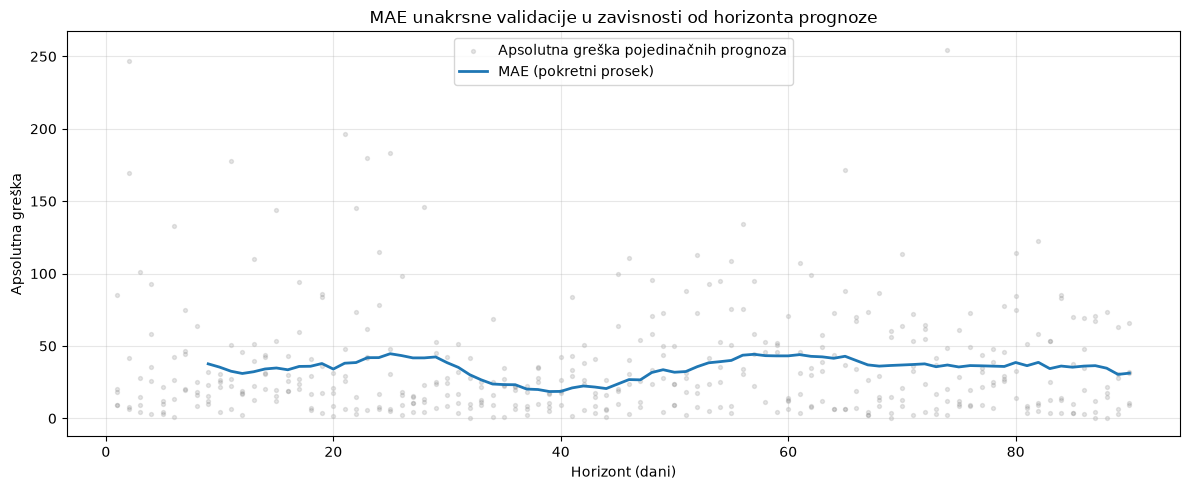

In [39]:
m3, fc3 = fit_and_evaluate("M3: optimizovani (CV)", build_model(best_params))

df_cv_best = cross_validation(m3, initial="730 days", period="120 days", horizon="90 days", disable_tqdm=True)
perf_best = performance_metrics(df_cv_best)
display(perf_best[["horizon", "mae", "rmse", "coverage"]].iloc[::10])

cv_horizon_days = (df_cv_best["ds"] - df_cv_best["cutoff"]).dt.days
cv_abs_error = (df_cv_best["y"] - df_cv_best["yhat"]).abs()
perf_horizon_days = perf_best["horizon"].dt.days

plt.figure(figsize=(12, 5))
plt.scatter(cv_horizon_days, cv_abs_error, s=8, alpha=0.2, color="grey",
            label="Apsolutna greška pojedinačnih prognoza")
plt.plot(perf_horizon_days, perf_best["mae"], color="tab:blue", linewidth=2,
         label="MAE (pokretni prosek)")
plt.title("MAE unakrsne validacije u zavisnosti od horizonta prognoze")
plt.xlabel("Horizont (dani)")
plt.ylabel("Apsolutna greška")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Grafik pokazuje kako se greška menja sa dužinom horizonta. Pošto Prophet ne koristi prethodne vrednosti serije, greška na kratkom i dugom horizontu je slična.

## 11. Rezultati na test skupu
### 11.1 Poređenje svih modela

,MAE,RMSE,MAPE (%),WAPE (%)
M1: + US praznici i događaji,42.08,59.38,27.64,16.79
M3: optimizovani (CV),45.51,58.12,24.09,18.15
M2: + multiplikativno + active_stores,45.81,58.47,24.27,18.27
M0: Prophet podrazumevani,51.29,83.85,28.88,20.46
Prosek dana u nedelji (8 ned.),70.37,122.72,25.42,28.07
Sezonski naivni,84.48,134.69,30.20,33.69


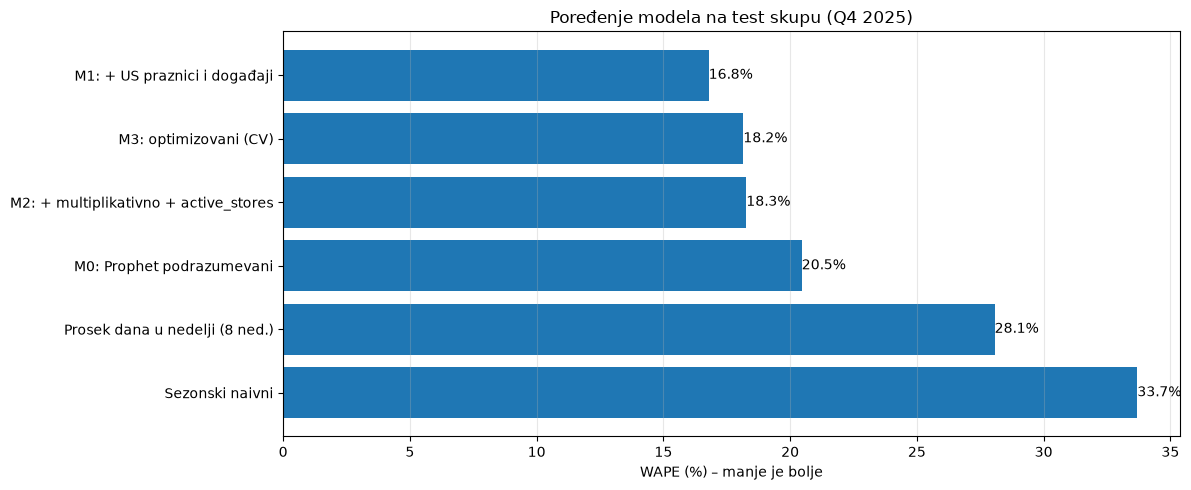

Najbolji model na testu: M1: + US praznici i događaji
Smanjenje WAPE od M0 do M3: 20.5% -> 18.2% (11% relativno)


In [40]:
comparison = pd.DataFrame(results).T.sort_values("WAPE (%)")
display(comparison.round(2))

plt.figure(figsize=(12, 5))
bars = plt.barh(comparison.index[::-1], comparison["WAPE (%)"][::-1])
plt.bar_label(bars, fmt="%.1f%%")
plt.xlabel("WAPE (%) – manje je bolje")
plt.title("Poređenje modela na test skupu (Q4 2025)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

best_name = comparison.index[0]
m0_wape = results["M0: Prophet podrazumevani"]["WAPE (%)"]
m3_wape = results["M3: optimizovani (CV)"]["WAPE (%)"]
print(f"Najbolji model na testu: {best_name}")
print(f"Smanjenje WAPE od M0 do M3: {m0_wape:.1f}% -> {m3_wape:.1f}% ({(m0_wape - m3_wape) / m0_wape:.0%} relativno)")

### 11.2 Prognoza optimizovanog modela na test periodu

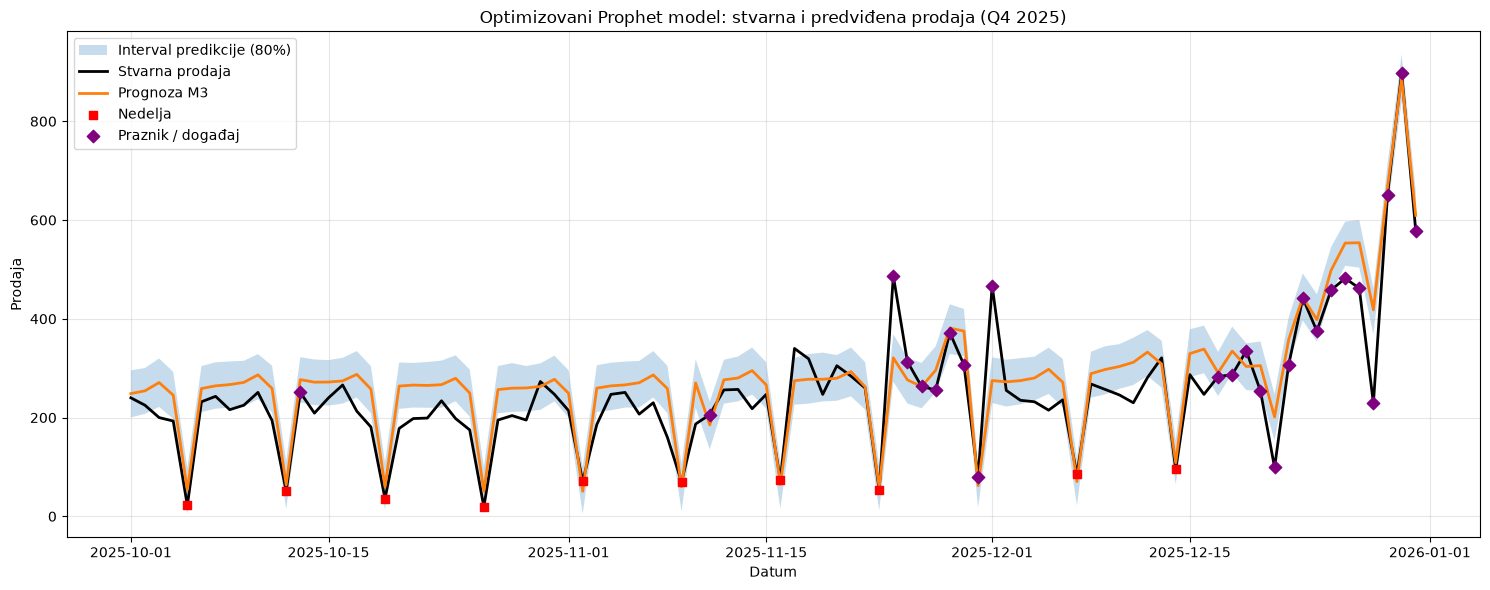

Udeo stvarnih vrednosti unutar 80% intervala: 59.8%


In [41]:
test_compare = test.copy()
test_compare["yhat"] = fc3["yhat"].to_numpy()
test_compare["yhat_lower"] = fc3["yhat_lower"].to_numpy()
test_compare["yhat_upper"] = fc3["yhat_upper"].to_numpy()
test_compare["Day_Type"] = np.where(test_compare["ds"].dt.weekday == 6, "Nedelja", "Pon–Sub")

event_days = set()
for _, r in HOLIDAYS.iterrows():
    for k in range(r["lower_window"], r["upper_window"] + 1):
        event_days.add(r["ds"] + pd.Timedelta(days=k))
test_compare.loc[test_compare["ds"].isin(event_days), "Day_Type"] = "Praznik / događaj"

plt.figure(figsize=(15, 6))
plt.fill_between(test_compare["ds"], test_compare["yhat_lower"], test_compare["yhat_upper"],
                 alpha=0.25, label="Interval predikcije (80%)")
plt.plot(test_compare["ds"], test_compare["y"], color="black", linewidth=2, label="Stvarna prodaja")
plt.plot(test_compare["ds"], test_compare["yhat"], color="tab:orange", linewidth=2, label="Prognoza M3")
for day_type, marker, color in [("Nedelja", "s", "red"), ("Praznik / događaj", "D", "purple")]:
    sub = test_compare[test_compare["Day_Type"] == day_type]
    plt.scatter(sub["ds"], sub["y"], marker=marker, color=color, s=40, zorder=3, label=day_type)
plt.title("Optimizovani Prophet model: stvarna i predviđena prodaja (Q4 2025)")
plt.xlabel("Datum")
plt.ylabel("Prodaja")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

coverage = ((test_compare["y"] >= test_compare["yhat_lower"]) & (test_compare["y"] <= test_compare["yhat_upper"])).mean()
print(f"Udeo stvarnih vrednosti unutar 80% intervala: {coverage:.1%}")

In [42]:
err_by_type = test_compare.groupby("Day_Type").apply(
    lambda g: pd.Series(evaluate(g["y"], g["yhat"])), include_groups=False)
err_by_type["Broj dana"] = test_compare["Day_Type"].value_counts()
err_by_type.round(2)

,MAE,RMSE,MAPE (%),WAPE (%),Broj dana
Day_Type,,,,,
Nedelja,17.29,19.32,49.76,30.02,10
Pon–Sub,46.87,53.26,21.73,20.01,57
Praznik / događaj,53.70,76.25,19.18,14.69,25


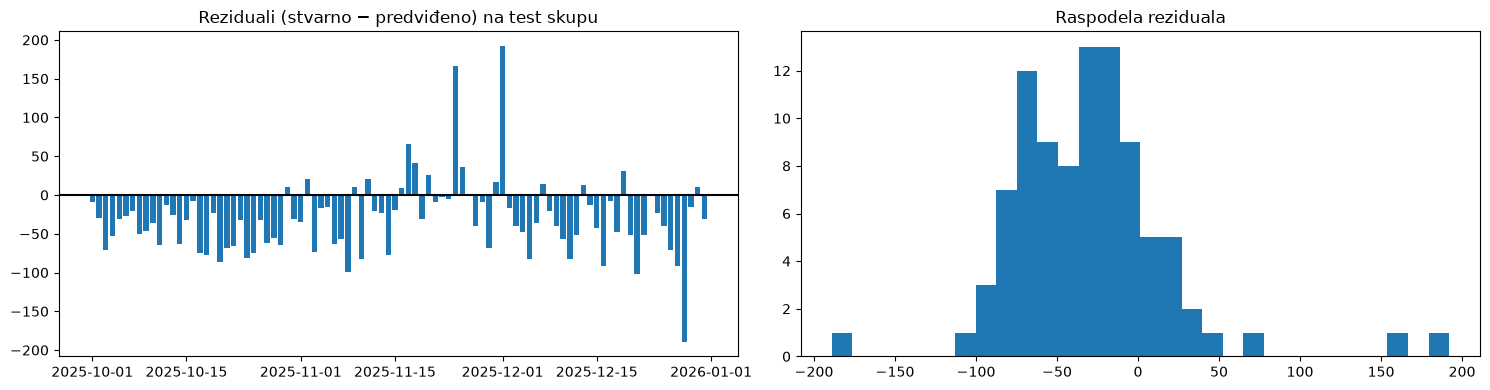

Prosečan rezidual (pristrasnost): -30.7


In [43]:
test_compare["residual"] = test_compare["y"] - test_compare["yhat"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].bar(test_compare["ds"], test_compare["residual"])
axes[0].axhline(0, color="black")
axes[0].set_title("Reziduali (stvarno − predviđeno) na test skupu")
axes[1].hist(test_compare["residual"], bins=30)
axes[1].set_title("Raspodela reziduala")
plt.tight_layout()
plt.show()

print("Prosečan rezidual (pristrasnost): {:.1f}".format(test_compare["residual"].mean()))

### 11.3 Komponente modela i tačke promene trenda

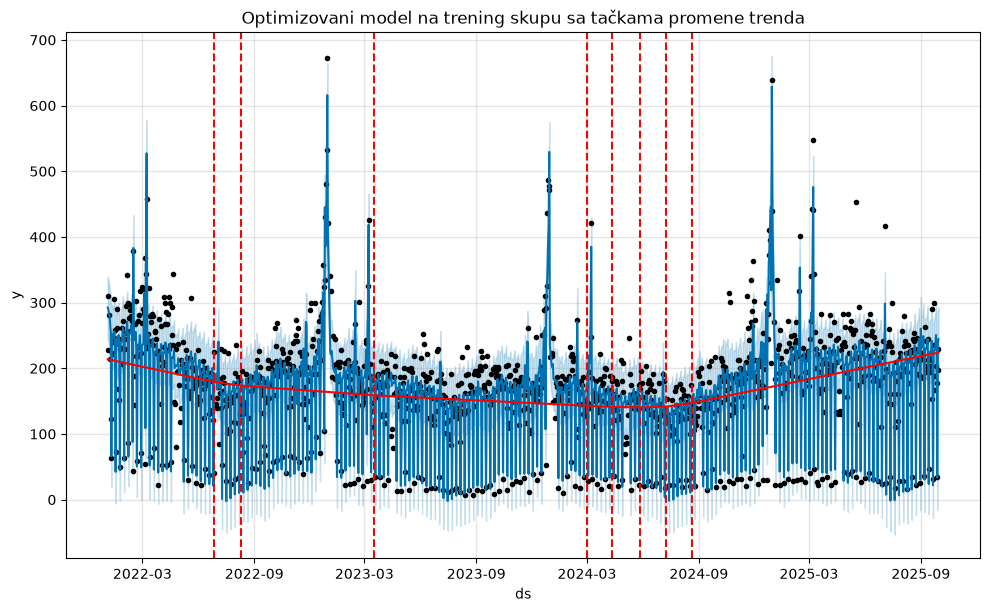

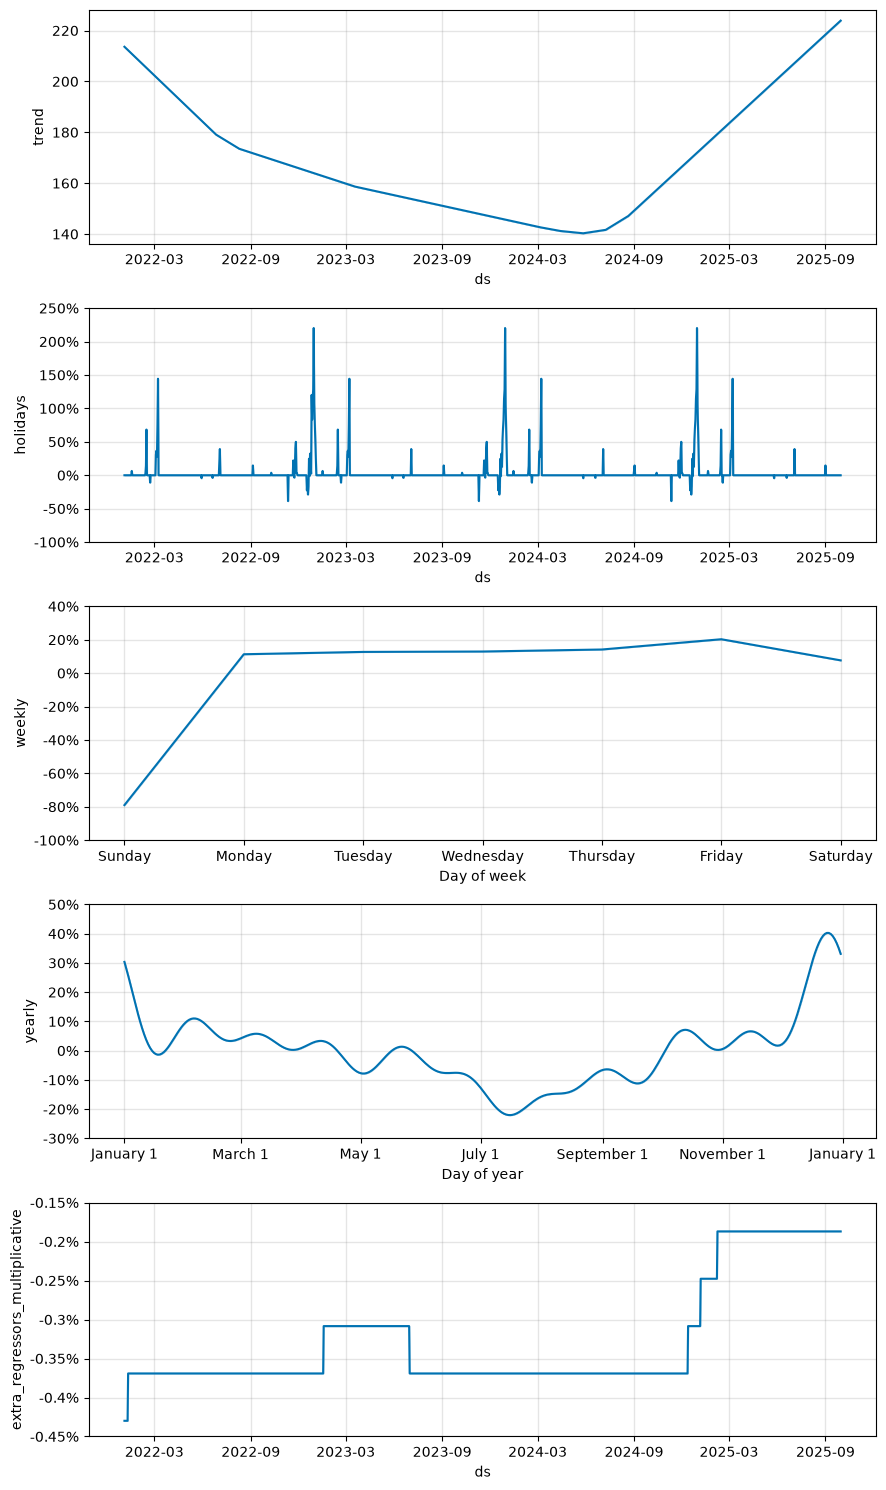

In [44]:
fc3_full = m3.predict(m3.history[["ds", "active_stores"]])
fig = m3.plot(fc3_full)
add_changepoints_to_plot(fig.gca(), m3, fc3_full)
plt.title("Optimizovani model na trening skupu sa tačkama promene trenda")
plt.show()

fig = m3.plot_components(fc3_full)
plt.show()

Grafik komponenti prikazuje ono što je utvrđeno u analizi sezonalnosti:

- **trend** prati promenu nivoa prodaje, a regresor `active_stores` preuzima deo skokova izazvanih otvaranjem i zatvaranjem prodavnica,
- **holidays** komponenta pokazuje efekte američkih praznika (zatvaranje na New Year's Day, povećanje na Christmas Day, Independence Day i Labor Day) i pikove za 8. mart, Valentine's Day, Black Friday i prazničnu sezonu,
- **weekly** komponenta pokazuje veliki pad nedeljom,
- **yearly** komponenta pokazuje slabije leto i jaču zimu,
- **extra_regressors** pokazuje doprinos broja aktivnih prodavnica.

## 12. Mesečni nivo

Za mesečni nivo porede se dva pristupa:

1. **Prophet treniran na mesečnim podacima** – nedeljna sezonalnost se isključuje (nema smisla za mesečne podatke), a kao regresori se koriste prosečan broj aktivnih prodavnica i broj radnih dana u mesecu.
2. **Zbir dnevnih prognoza** optimizovanog modela M3.

In [45]:
cal = pd.DataFrame({"ds": pd.date_range("2022-01-01", "2027-12-31", freq="D")})
cal["active_stores"] = active_stores(cal["ds"])
cal["open_day"] = ((cal["ds"].dt.weekday < 6) & ~cal["ds"].isin(CLOSED_DAYS)).astype(int)
cal_month = cal.groupby(pd.Grouper(key="ds", freq="MS")).agg(active_stores=("active_stores", "mean"),
                                                             working_days=("open_day", "sum")).reset_index()

prophet_monthly = (prophet_df.groupby(pd.Grouper(key="ds", freq="MS"))["y"].sum().reset_index()
                   .merge(cal_month, on="ds", how="left"))

train_m = prophet_monthly[prophet_monthly["ds"] < TEST_START].copy()
test_m = prophet_monthly[prophet_monthly["ds"] >= TEST_START].copy()

def build_monthly_model():
    m = Prophet(weekly_seasonality=False, daily_seasonality=False, yearly_seasonality=6,
                seasonality_mode="multiplicative", changepoint_prior_scale=0.05)
    m.add_regressor("active_stores")
    m.add_regressor("working_days")
    return m

model_m = build_monthly_model()
model_m.fit(train_m)
fc_m = model_m.predict(test_m[["ds", "active_stores", "working_days"]])

test_m["Prophet mesečni"] = fc_m["yhat"].to_numpy()
test_m["Zbir dnevnih (M3)"] = (test_compare.groupby(pd.Grouper(key="ds", freq="MS"))["yhat"].sum().reindex(test_m["ds"]).to_numpy())

display(test_m[["ds", "y", "Prophet mesečni", "Zbir dnevnih (M3)"]].round(0))
pd.DataFrame({name: evaluate(test_m["y"], test_m[name]) for name in ["Prophet mesečni", "Zbir dnevnih (M3)"]}).T.round(2)

20:56:54 - cmdstanpy - INFO - Chain [1] start processing
20:56:55 - cmdstanpy - INFO - Chain [1] done processing


,ds,y,Prophet mesečni,Zbir dnevnih (M3)
45,2025-10-01,6003,6627.0,7400.0
46,2025-11-01,6966,6392.0,7301.0
47,2025-12-01,10097,9063.0,11185.0


,MAE,RMSE,MAPE (%),WAPE (%)
Prophet mesečni,743.85,771.86,9.62,9.67
Zbir dnevnih (M3),940.11,1040.57,12.95,12.23


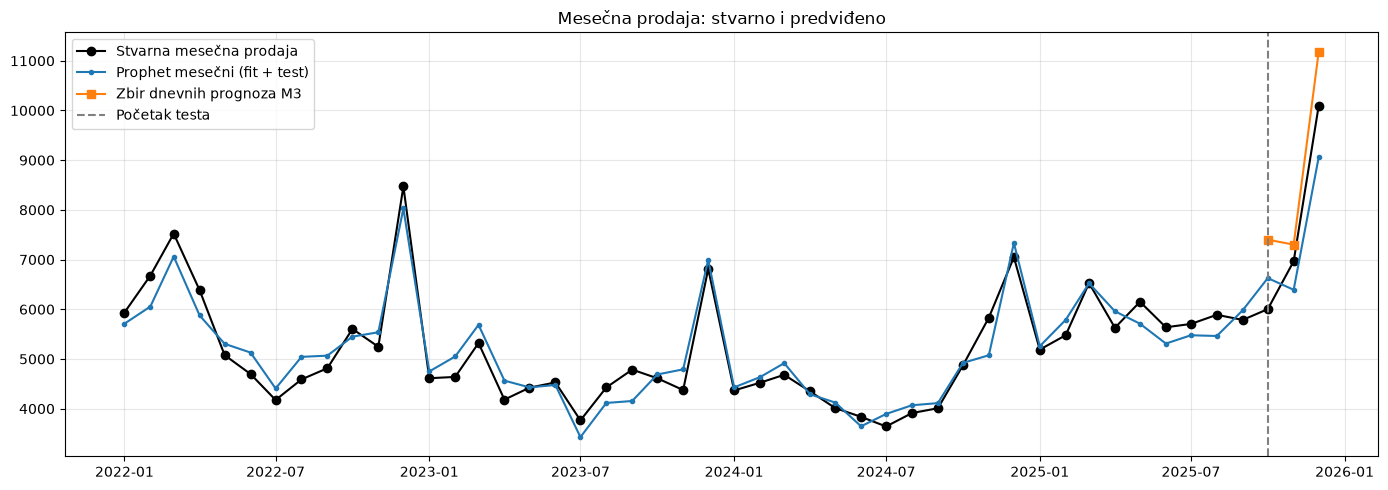

In [46]:
fc_m_hist = model_m.predict(prophet_monthly[["ds", "active_stores", "working_days"]])

plt.figure(figsize=(14, 5))
plt.plot(prophet_monthly["ds"], prophet_monthly["y"], marker="o", color="black", label="Stvarna mesečna prodaja")
plt.plot(fc_m_hist["ds"], fc_m_hist["yhat"], marker=".", label="Prophet mesečni (fit + test)")
plt.plot(test_m["ds"], test_m["Zbir dnevnih (M3)"], marker="s", label="Zbir dnevnih prognoza M3")
plt.axvline(TEST_START, color="grey", linestyle="--", label="Početak testa")
plt.title("Mesečna prodaja: stvarno i predviđeno")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Mesečni model ima samo 45 tačaka za treniranje, pa je osetljiviji na pojedinačne godine. Dnevni model koristi mnogo više informacija (dan u nedelji, tačne datume događaja), pa je **sabiranje dnevne prognoze** obično stabilniji način da se dobije mesečna prognoza. Mesečni model je koristan kao brza kontrola.

### 12.1 Godišnji nivo

Godišnja agregacija ima **samo 4 tačke** (2022–2025). Prophet sa toliko podataka ne može da proceni ni trend sa tačkama promene ni sezonalnost, pa bi „prognoza" bila samo proizvoljna linija kroz 4 tačke. Zato se Prophet **ne trenira direktno** na godišnjim podacima. Godišnja prognoza za 2026. dobija se sabiranjem dnevne prognoze i upoređuje sa zbirom mesečne prognoze.

## 13. Finalna prognoza za 2026. godinu

Optimizovani model se ponovo trenira na **svim** podacima (2022–2025) i pravi dnevnu prognozu za 365 dana unapred. Pretpostavka je da tokom 2026. radi 7 prodavnica koje su bile aktivne krajem 2025. Poznati neradni dani (New Year's Day, 2. januar, 7. januar, 1. maj, uskršnja nedelja) postavljaju se na 0. Američki praznici i trgovinski događaji za 2026. već su u tabeli `HOLIDAYS`, pa ih model automatski uzima u obzir.

In [47]:
final_model = build_model(best_params)
final_model.fit(prophet_df[["ds", "y", "active_stores"]])

future = final_model.make_future_dataframe(periods=365, freq="D")
future["active_stores"] = active_stores(future["ds"])
forecast = predict_clean(final_model, future)

forecast_2026 = forecast[forecast["ds"] > prophet_df["ds"].max()][["ds", "yhat", "yhat_lower", "yhat_upper"]]
forecast_2026.head(10).round(1)

20:56:57 - cmdstanpy - INFO - Chain [1] start processing
20:56:57 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
1435,2026-01-01,0.0,0.0,0.0
1436,2026-01-02,0.0,0.0,0.0
1437,2026-01-03,291.1,242.5,338.0
1438,2026-01-04,90.4,38.7,134.7
1439,2026-01-05,290.0,244.1,339.4
1440,2026-01-06,289.2,242.9,339.2
1441,2026-01-07,0.0,0.0,0.0
1442,2026-01-08,282.2,231.2,329.6
1443,2026-01-09,289.0,241.7,336.4
1444,2026-01-10,256.6,211.1,303.5


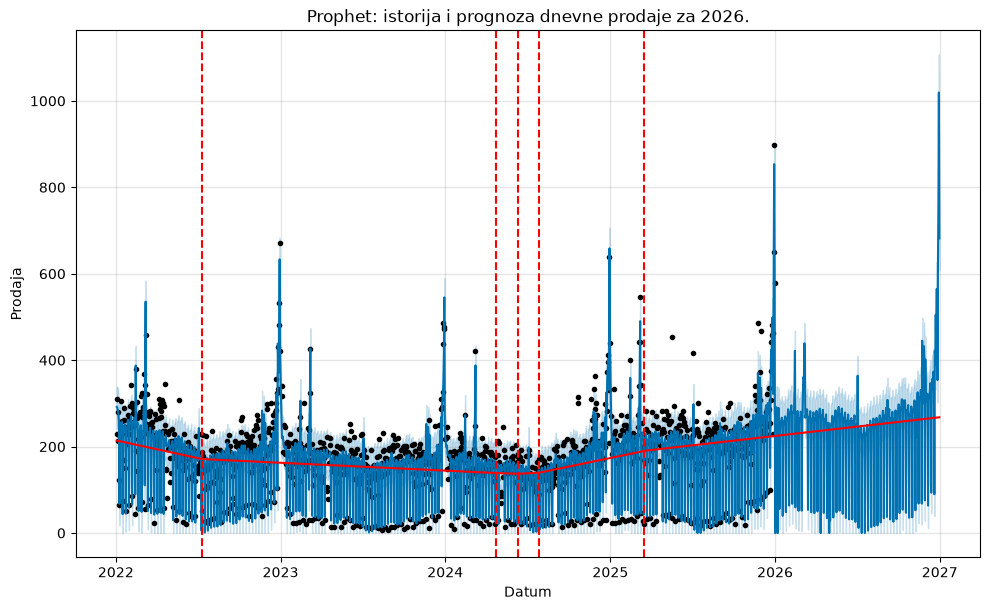

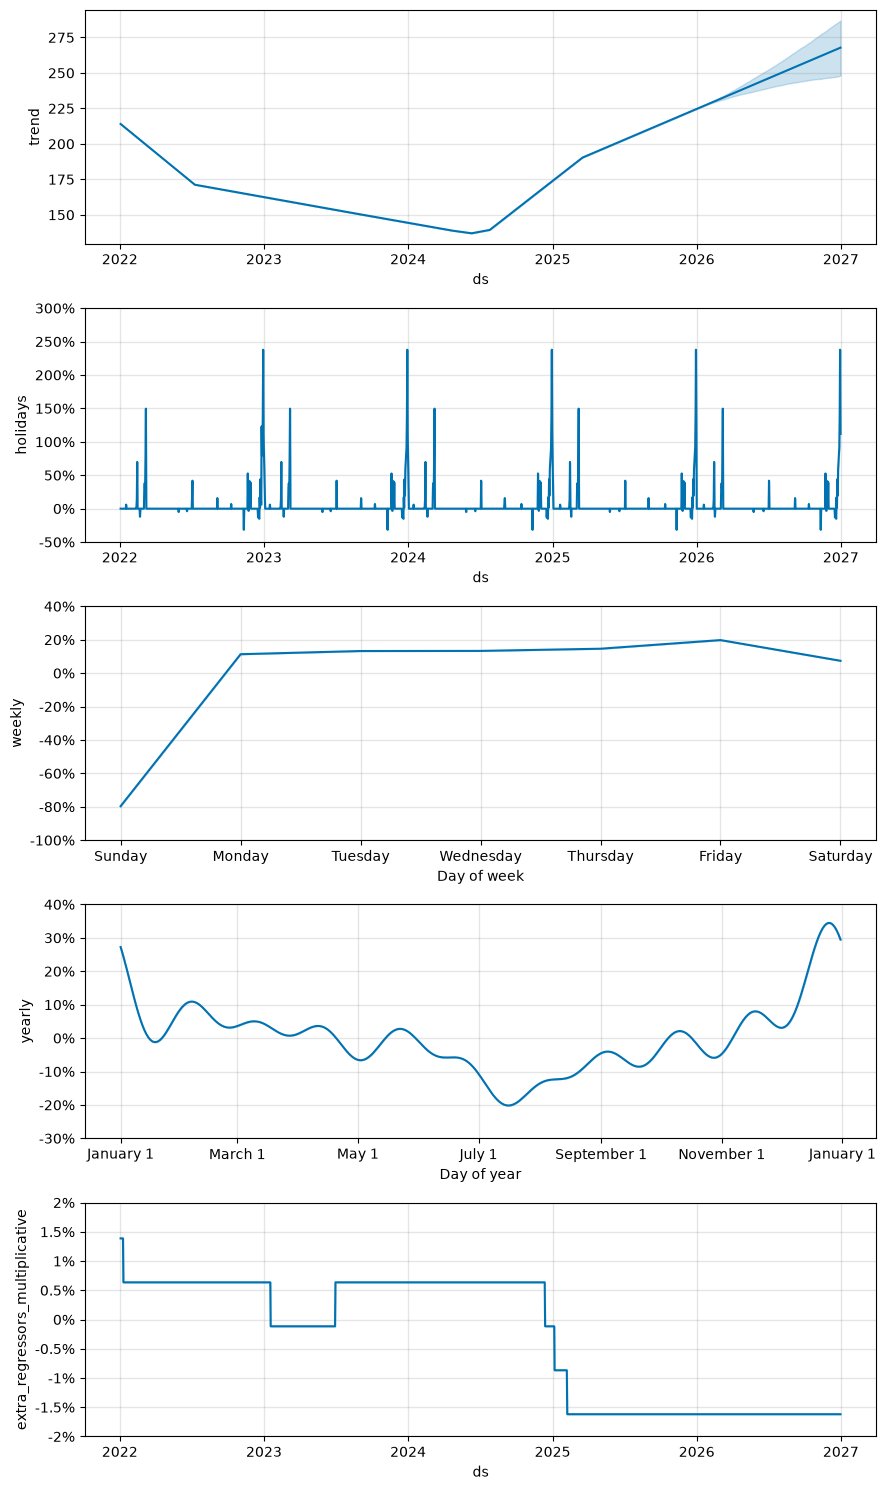

In [48]:
fig = final_model.plot(forecast)
add_changepoints_to_plot(fig.gca(), final_model, forecast)
plt.title("Prophet: istorija i prognoza dnevne prodaje za 2026.")
plt.xlabel("Datum")
plt.ylabel("Prodaja")
plt.show()

fig = final_model.plot_components(forecast)
plt.show()

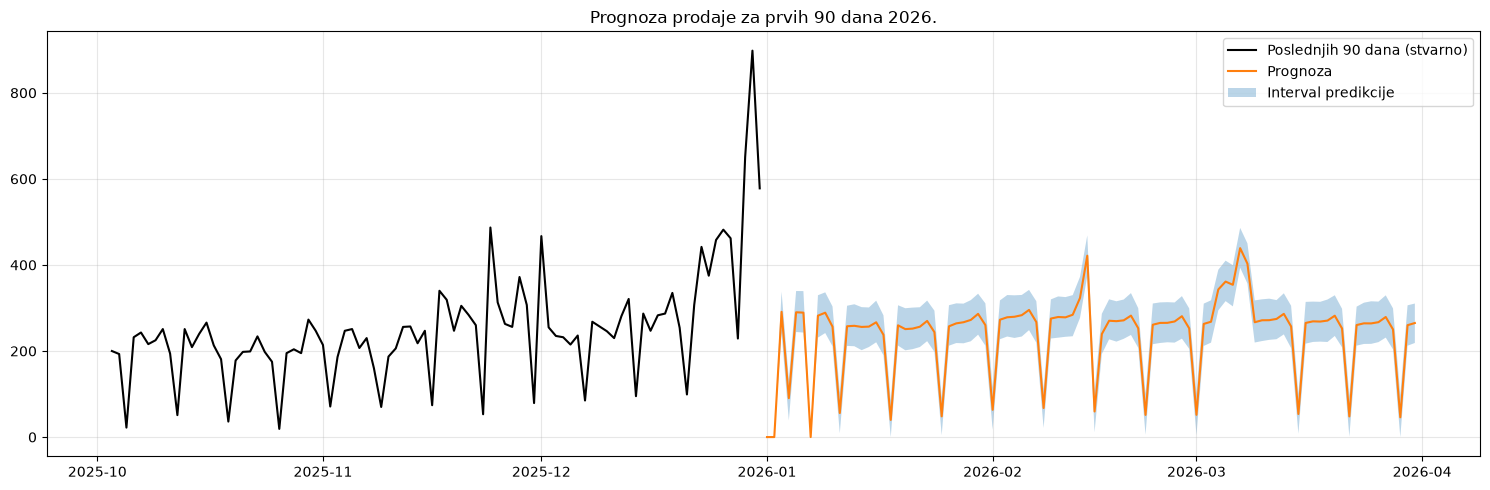

In [49]:
first_90 = forecast_2026.head(90)

plt.figure(figsize=(15, 5))
plt.plot(prophet_df["ds"].tail(90), prophet_df["y"].tail(90), color="black", label="Poslednjih 90 dana (stvarno)")
plt.plot(first_90["ds"], first_90["yhat"], color="tab:orange", label="Prognoza")
plt.fill_between(first_90["ds"], first_90["yhat_lower"], first_90["yhat_upper"], alpha=0.3, label="Interval predikcije")
plt.title("Prognoza prodaje za prvih 90 dana 2026.")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

20:57:01 - cmdstanpy - INFO - Chain [1] start processing
20:57:01 - cmdstanpy - INFO - Chain [1] done processing


,Prognoza (zbir dnevne),Prognoza (mesečni model),Stvarno 2025
ds,,,
2026-01-01,6605.0,6250.0,5188
2026-02-01,6960.0,6462.0,5478
2026-03-01,7976.0,7133.0,6527
2026-04-01,7038.0,6532.0,5628
2026-05-01,6843.0,5908.0,6151
2026-06-01,6854.0,6176.0,5638
2026-07-01,6489.0,5910.0,5705
2026-08-01,6699.0,6091.0,5889
2026-09-01,7165.0,6536.0,5786


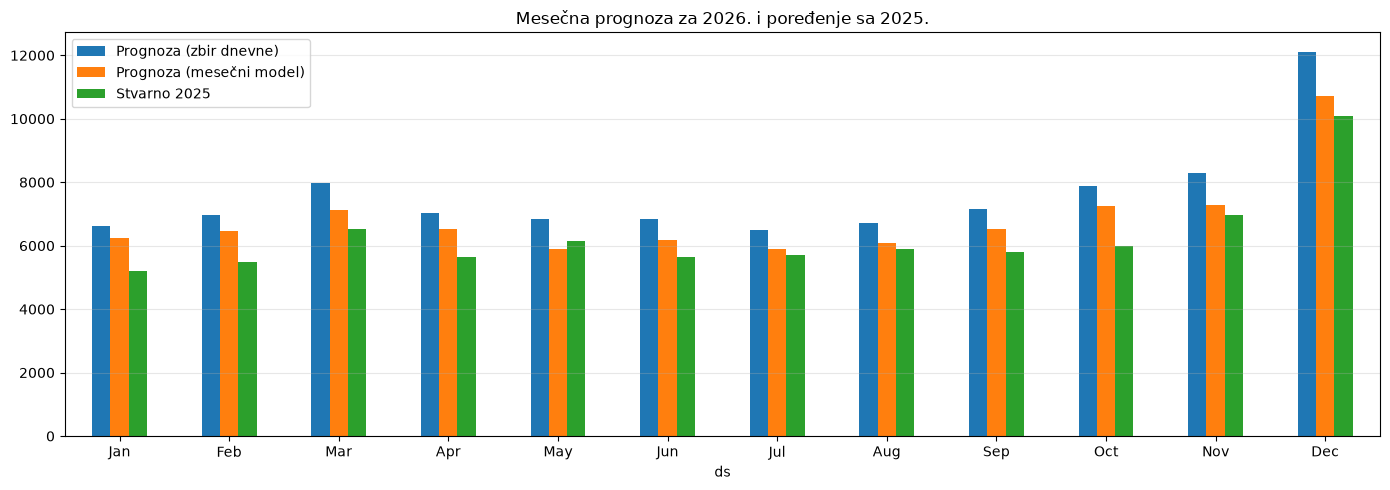

In [50]:
monthly_2026 = (forecast_2026.groupby(pd.Grouper(key="ds", freq="MS"))["yhat"].sum().rename("Prognoza (zbir dnevne)").to_frame())

model_m_full = build_monthly_model()
model_m_full.fit(prophet_monthly)
future_m = cal_month[(cal_month["ds"] >= "2026-01-01") & (cal_month["ds"] <= "2026-12-01")].copy()
monthly_2026["Prognoza (mesečni model)"] = model_m_full.predict(future_m)["yhat"].to_numpy()
monthly_2026["Stvarno 2025"] = prophet_monthly.set_index("ds")["y"].loc["2025"].to_numpy()

display(monthly_2026.round(0))

plot_df = monthly_2026.copy()
plot_df.index = plot_df.index.strftime("%b")
plot_df.plot(kind="bar", figsize=(14, 5), rot=0)
plt.title("Mesečna prognoza za 2026. i poređenje sa 2025.")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

,Year,Prodaja,Tip
0,2022,69192.0,Stvarno
1,2023,56485.0,Stvarno
2,2024,55080.0,Stvarno
3,2025,75056.0,Stvarno
4,2026,90914.0,Prognoza (dnevni model)
5,2026,82229.0,Prognoza (mesečni model)


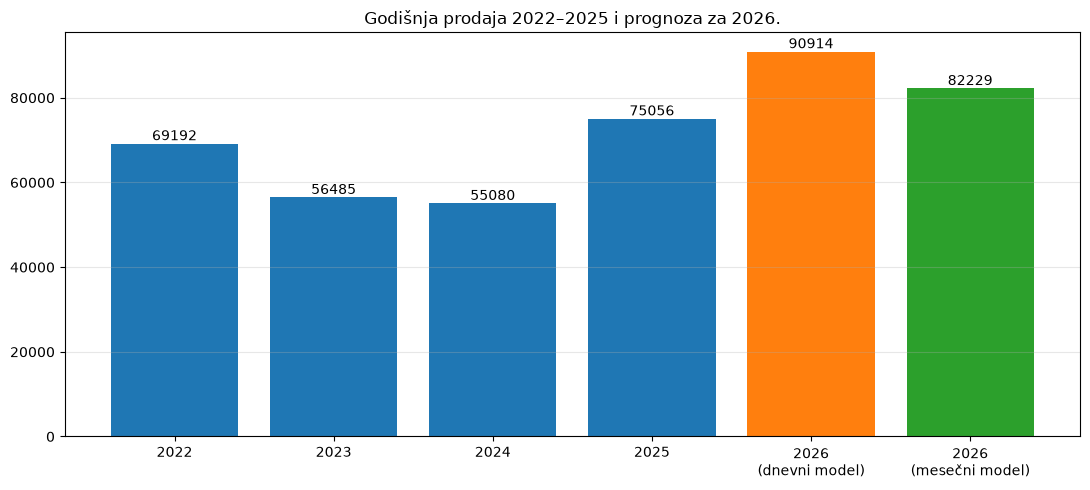

In [51]:
yearly_view = yearly_sales.rename(columns={"Sold_Quantity": "Prodaja"}).assign(Tip="Stvarno")
yearly_view = pd.concat([
    yearly_view,
    pd.DataFrame([{"Year": 2026, "Prodaja": forecast_2026["yhat"].sum(), "Tip": "Prognoza (dnevni model)"},
                  {"Year": 2026, "Prodaja": monthly_2026["Prognoza (mesečni model)"].sum(), "Tip": "Prognoza (mesečni model)"}])
], ignore_index=True)
display(yearly_view.round(0))

colors = yearly_view["Tip"].map({"Stvarno": "tab:blue", "Prognoza (dnevni model)": "tab:orange",
                                 "Prognoza (mesečni model)": "tab:green"})
labels = yearly_view["Year"].astype(str) + np.where(yearly_view["Tip"] == "Stvarno", "", "\n" + yearly_view["Tip"].str.replace("Prognoza ", ""))
plt.figure(figsize=(11, 5))
bars = plt.bar(labels, yearly_view["Prodaja"], color=colors)
plt.bar_label(bars, fmt="%.0f")
plt.title("Godišnja prodaja 2022–2025 i prognoza za 2026.")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [52]:
forecast_2026.to_excel("forecast_2026_daily.xlsx", index=False)
monthly_2026.to_excel("forecast_2026_monthly.xlsx")
print("Prognoze su sačuvane u forecast_2026_daily.xlsx i forecast_2026_monthly.xlsx")

Prognoze su sačuvane u forecast_2026_daily.xlsx i forecast_2026_monthly.xlsx


## 14. Upotrebljivost modela na nivou prodavnice

U e-commerce i maloprodajnim sistemima prognoza je često potrebna i na nižem nivou (prodavnica, kategorija, artikal). Isti postupak (optimizovani parametri, praznici i događaji) primenjuje se na prodavnice koje su radile ceo trening i test period, kako bi se videlo kako tačnost zavisi od obima prodaje.

20:57:03 - cmdstanpy - INFO - Chain [1] start processing
20:57:04 - cmdstanpy - INFO - Chain [1] done processing
20:57:05 - cmdstanpy - INFO - Chain [1] start processing
20:57:05 - cmdstanpy - INFO - Chain [1] done processing
20:57:06 - cmdstanpy - INFO - Chain [1] start processing
20:57:07 - cmdstanpy - INFO - Chain [1] done processing
20:57:08 - cmdstanpy - INFO - Chain [1] start processing
20:57:08 - cmdstanpy - INFO - Chain [1] done processing


,Lokacija,Prosečna dnevna prodaja,MAE,RMSE,MAPE (%),WAPE (%)
3,RT_SANTAFE,66.85,22.90,38.95,36.62,31.32
2,RT_ORLANDO,61.62,13.98,17.67,32.27,25.85
1,RT_NEWYORK,39.04,10.40,12.61,34.07,25.11
0,RT_LOSANG,13.67,8.33,11.46,40.96,35.79


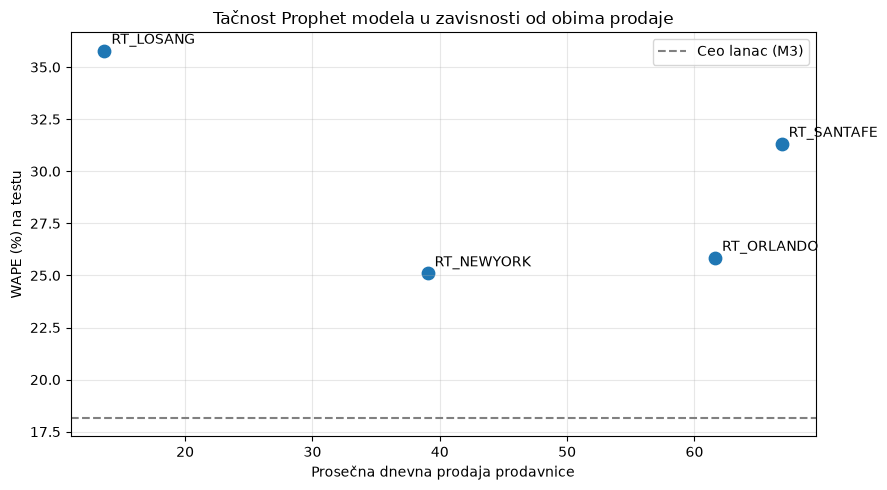

In [53]:
store_rows = []
chain_open_days = prophet_df["ds"] 

for loc, life in store_life.iterrows():
    if life["first_sale"] > TEST_START - pd.Timedelta(days=730) or not life["aktivna_na_kraju"]:
        continue   
    s = (df[df["Location Code"] == loc].groupby("Created Date")["Sold_Quantity"].sum())
    dates = chain_open_days[(chain_open_days >= life["first_sale"]) & (chain_open_days <= life["last_sale"])]
    s = s.reindex(dates, fill_value=0)      
    sdf = pd.DataFrame({"ds": s.index, "y": s.values})

    s_train, s_test = sdf[sdf["ds"] < TEST_START], sdf[sdf["ds"] >= TEST_START]
    m = build_model(best_params, use_regressor=False)
    m.fit(s_train)
    fc = predict_clean(m, s_test[["ds"]])
    store_rows.append({"Lokacija": loc,
                       "Prosečna dnevna prodaja": s_train["y"].mean(),
                       **evaluate(s_test["y"], fc["yhat"])})

store_results = pd.DataFrame(store_rows).sort_values("Prosečna dnevna prodaja", ascending=False)
display(store_results.round(2))

plt.figure(figsize=(9, 5))
plt.scatter(store_results["Prosečna dnevna prodaja"], store_results["WAPE (%)"], s=80)
for _, r in store_results.iterrows():
    plt.annotate(r["Lokacija"], (r["Prosečna dnevna prodaja"], r["WAPE (%)"]),
                 textcoords="offset points", xytext=(5, 5))
plt.axhline(results["M3: optimizovani (CV)"]["WAPE (%)"], color="grey", linestyle="--", label="Ceo lanac (M3)")
plt.xlabel("Prosečna dnevna prodaja prodavnice")
plt.ylabel("WAPE (%) na testu")
plt.title("Tačnost Prophet modela u zavisnosti od obima prodaje")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 15. Analiza upotrebljivosti Prophet modela za ovakve situacije

**Koraci optimizacije načina korišćenja modela** (doprinos svakog koraka vidi se u tabeli iz poglavlja 11 i u automatskom sažetku ispod):

**Kada je Prophet dobar izbor (kao u ovom skupu):**
- jaka i stabilna nedeljna i godišnja sezonalnost,
- jasni kalendarski događaji koji se ponavljaju,
- bar 2–3 godine dnevnih podataka,
- potreba za interpretabilnim modelom (komponente su razumljive i menadžmentu),
- srednjoročni horizont (nedelje i meseci), npr. planiranje nabavke i zaposlenih.

**Ograničenja uočena na ovom skupu:**
- Model ne koristi prethodne vrednosti, pa ne reaguje na neočekivane promene nivoa.
- Pikovi koji se menjaju iz godine u godinu (npr. rast novogodišnje prodaje 2025.) se delimično potcenjuju, jer model uči prosečan efekat događaja.
- Otvaranje nove prodavnice mora biti unapred poznato i uneto kao regresor; bez toga model pogrešno tumači skok kao promenu trenda.
- Na malim serijama (manje prodavnice, artikli) relativna greška značajno raste.
- U skupu nema podataka o cenama, akcijama i marketingu; njihovo uvođenje kao regresora verovatno bi najviše popravilo prognozu.

**Poređenje sa referentnim modelima** pokazuje da li se složeniji model isplati: ako optimizovani Prophet ima manji WAPE od jednostavnih sezonskih modela, njegova upotreba je opravdana, uz dodatnu prednost intervala nesigurnosti i interpretabilnih komponenti.

In [54]:
baselines = ["Sezonski naivni", "Prosek dana u nedelji (8 ned.)"]
best_baseline = min(baselines, key=lambda n: results[n]["WAPE (%)"])
prophet_models = [n for n in results if n.startswith("M")]
best_prophet = min(prophet_models, key=lambda n: results[n]["WAPE (%)"])

print("Doprinos pojedinačnih koraka (WAPE na testu):")
for n in prophet_models:
    print(f"  {n:<40} {results[n]['WAPE (%)']:6.2f}%")
print(f"\nNajbolji referentni model: {best_baseline} ({results[best_baseline]['WAPE (%)']:.2f}%)")
print(f"Najbolji Prophet model:    {best_prophet} ({results[best_prophet]['WAPE (%)']:.2f}%)")

diff = results[best_baseline]["WAPE (%)"] - results[best_prophet]["WAPE (%)"]
if diff > 0:
    print(f"\nProphet je bolji od najboljeg referentnog modela za {diff:.2f} procentnih poena WAPE-a.")
else:
    print(f"\nReferentni model je bolji za {-diff:.2f} p.p. Na ovom horizontu Prophet ne donosi dobitak u tačnosti; "
          "njegova vrednost je tada u interpretaciji komponenti, intervalima i dugoročnoj prognozi.")
print(f"Pokrivenost 80% intervala na testu: {coverage:.1%} (idealno ≈ 80%)")

Doprinos pojedinačnih koraka (WAPE na testu):
  M0: Prophet podrazumevani                 20.46%
  M1: + US praznici i događaji              16.79%
  M2: + multiplikativno + active_stores     18.27%
  M3: optimizovani (CV)                     18.15%

Najbolji referentni model: Prosek dana u nedelji (8 ned.) (28.07%)
Najbolji Prophet model:    M1: + US praznici i događaji (16.79%)

Prophet je bolji od najboljeg referentnog modela za 11.28 procentnih poena WAPE-a.
Pokrivenost 80% intervala na testu: 59.8% (idealno ≈ 80%)


## 16. Zaključak

U projektu je analizirana biblioteka Prophet – njen matematički model (trend sa tačkama promene, Furijeova sezonalnost, praznici sa prozorima, dodatni regresori, intervali nesigurnosti), način pripreme podataka (`ds`/`y`, agregacija, rad sa nedostajućim vrednostima, regresori poznati unapred) i način pripreme i ocene modela (parametri, `cross_validation`, `performance_metrics`).

Na skupu `DemoRetail22-25` (≈249.000 prodajnih stavki, 8 prodavnica, 2022–2025) analiza je pokazala jaku nedeljnu sezonalnost (nedelja ≈ 20% običnog dana), izraženu godišnju sezonalnost sa pikom u decembru, jake jednodnevne efekte (8. mart, kraj decembra, 14. februar) i strukturne promene usled otvaranja i zatvaranja prodavnica. Američki praznici imaju različite efekte – od zatvaranja (New Year's Day) do povećane prodaje (Christmas Day, Independence Day, Labor Day).

Na osnovu toga model je unapređen korak po korak (M0 → M3): uvedeni su američki savezni praznici i trgovinski događaji, multiplikativna sezonalnost, regresor broja aktivnih prodavnica i hiperparametri izabrani unakrsnom validacijom. Tačnost je upoređena sa referentnim modelima na test periodu Q4 2025, a zatim je napravljena dnevna, mesečna i godišnja prognoza za 2026. godinu.

Prophet je **upotrebljiv alat za predikciju agregirane prodaje** u e-commerce i maloprodajnim sistemima kada postoje jasni kalendarski obrasci i dovoljno istorije, posebno zbog interpretabilnosti i lakog uključivanja poslovnog znanja (praznici, događaji, broj prodavnica). Njegova ograničenja su nemogućnost korišćenja kratkoročne dinamike i slabija tačnost na malim i retkim serijama. Dalje unapređenje moguće je uvođenjem podataka o cenama, akcijama i marketinškim kampanjama kao regresora, kao i hijerarhijskim prognoziranjem (lanac → prodavnica → brend).